# DX602 Final Project
## Exploratory Data Analysis of NHL Game Statistics (2000-2020)

---

**Author:** Jacob Benigeri  
**Date:** November 22nd 2026  
**Boston University Online Master of Data Science**  

## 1. Introduction

For my final project, I selected the Sports - NHL Game Statistics dataset. This dataset contains data from Martin Ellis NHL game data, version 2. This dataset contains data from 2000 to 2020. The dataset has 23,735 rows and 30 columns. Each observation represents one game. Some of the key variables include game dates, teams that played, offensive performance data (goals, shots), defensive and physical performance data (blocked shots, hits), special teams (power-play opportunities and goals), and game outcomes (wins, losses or draws).

The goal of my project is to conduct an exploratory data analysis (EDA) of historical NHL game statistics to better understand team performance. More specifically, I am interested in analyzing home advantage and the relationship between offensive, defensive, and special teams statistics and game outcomes. Furthermore, I aim to investigate how the game has evolved over time by looking at trends in scoring and other performance metrics. I also intend to examine the differences in performance across NHL teams. Finally, I will use linear regression to examine and model relationships between selected numerical variables.

Some of the questions I would like to examine are:
- Do home teams win more frequently and score more goals than away teams?
- What is more strongly associated with winning games: strong offensive performance or strong defensive performance?
- How are power-play and penalty-kill efficiency associated with game outcomes?
- How have scoring and other performance metrics evolved between 2000 and 2020?
- Which regular-season performance metrics are most strongly associated with playoff success, and is offensive or defensive performance more strongly associated with postseason success?

## 2. Load and Inspect the Data

**2.1 Import Libraries**

In [1]:
# Import libraries required for analysis, including numpy in addition to those suggested in the instructions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

plt.close("all")

**2.2 Load the Dataset**

In [2]:
# Loading the NHL Game Data (2000-2020) Dataset
game_stats = pd.read_csv("game_stats_v2.csv")

# Display the first five rows
game_stats.head(5)

,game_id,date_time_GMT,home_team,away_team,home_won,home_settled_in,home_head_coach,home_goals,home_shots,home_hits,...,away_goals,away_shots,away_hits,away_pim,away_powerPlayOpportunities,away_powerPlayGoals,away_faceOffWinPercentage,away_giveaways,away_takeaways,away_blocked
0,2016020045,2016-10-19T00:30:00Z,Chicago Blackhawks,Philadelphia Flyers,True,REG,Joel Quenneville,7.0,28.0,20.0,...,4.0,27.0,30.0,6.0,4.0,2.0,50.9,12.0,9.0,11.0
1,2017020812,2018-02-07T00:00:00Z,Buffalo Sabres,Anaheim Ducks,False,OT,Phil Housley,3.0,33.0,17.0,...,4.0,34.0,16.0,6.0,3.0,1.0,43.8,7.0,4.0,14.0
2,2015020314,2015-11-24T01:00:00Z,Winnipeg Jets,Colorado Avalanche,False,REG,Paul Maurice,1.0,21.0,22.0,...,4.0,29.0,17.0,9.0,3.0,1.0,45.7,13.0,5.0,20.0
3,2015020849,2016-02-17T00:00:00Z,Carolina Hurricanes,Winnipeg Jets,True,REG,Bill Peters,2.0,29.0,16.0,...,1.0,21.0,21.0,10.0,4.0,0.0,31.4,4.0,14.0,16.0
4,2017020586,2017-12-30T03:00:00Z,Anaheim Ducks,Calgary Flames,True,REG,Randy Carlyle,2.0,41.0,15.0,...,1.0,23.0,20.0,19.0,3.0,0.0,54.7,10.0,4.0,7.0


In [3]:
# Display the dataset's dimensions
print("Number of rows:", game_stats.shape[0])
print("Number of columns:", game_stats.shape[1])

Number of rows: 23735
Number of columns: 30


**2.3 Inspect Columns and Data Types**

In [4]:
# Display all column names in the dataset and their data types
game_stats.info()
game_stats.dtypes.value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 23735 entries, 0 to 23734
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   game_id                      23735 non-null  int64  
 1   date_time_GMT                23735 non-null  str    
 2   home_team                    23730 non-null  str    
 3   away_team                    23730 non-null  str    
 4   home_won                     23735 non-null  bool   
 5   home_settled_in              23735 non-null  str    
 6   home_head_coach              23721 non-null  str    
 7   home_goals                   23731 non-null  float64
 8   home_shots                   23731 non-null  float64
 9   home_hits                    21271 non-null  float64
 10  home_pim                     23731 non-null  float64
 11  home_powerPlayOpportunities  23731 non-null  float64
 12  home_powerPlayGoals          23731 non-null  float64
 13  home_faceOffWinPercentage  

float64    20
str         7
bool        2
int64       1
Name: count, dtype: int64

**2.4 Assess Data Quality**

In [5]:
 #Calculate missing-value counts and percentages
missing_values = pd.DataFrame({
    "Missing Values": game_stats.isna().sum(),
    "Missing Percentage": game_stats.isna().mean() * 100
})
# Round percentages 
missing_values["Missing Percentage"] = missing_values["Missing Percentage"].round(2)

# Sort by missing-value count and display
missing_values.sort_values("Missing Values", ascending=False)

,Missing Values,Missing Percentage
away_faceOffWinPercentage,11074,46.66
home_faceOffWinPercentage,11074,46.66
home_takeaways,2464,10.38
home_hits,2464,10.38
away_takeaways,2464,10.38
away_giveaways,2464,10.38
away_hits,2464,10.38
home_blocked,2464,10.38
home_giveaways,2464,10.38
away_blocked,2464,10.38


In [6]:
# Check for fully duplicated rows
print("Duplicate rows:", game_stats.duplicated().sum())

# Check for duplicate game IDs
print("Duplicate game IDs:", game_stats["game_id"].duplicated().sum())

# Count unique game IDs
print("Unique game IDs:", game_stats["game_id"].nunique())


Duplicate rows: 0
Duplicate game IDs: 0
Unique game IDs: 23735


In [7]:
# Examine the date range of the dataset
print("First game:", game_stats["date_time_GMT"].min())
print("Last game:", game_stats["date_time_GMT"].max())

First game: 2000-10-04T23:00:00Z
Last game: 2020-09-29T00:00:00Z


In [8]:
# Examine unique values in selected categorical variables
print("Home game outcomes:", game_stats["home_won"].unique())
print("Away game outcomes:", game_stats["away_won"].unique())

print("Home settlement types:", game_stats["home_settled_in"].unique())
print("Away settlement types:", game_stats["away_settled_in"].unique())

Home game outcomes: [ True False]
Away game outcomes: [False  True]
Home settlement types: <ArrowStringArray>
['REG', 'OT', 'tbc']
Length: 3, dtype: str
Away settlement types: <ArrowStringArray>
['REG', 'OT', 'tbc']
Length: 3, dtype: str


**2.5 Initial Observations**

The dataset contains 23,735 rows and 30 columns. It predominantly contains numerical variables. The dataset has twenty floats, one integer identifier, seven strings and two Booleans. There are no duplicate rows or game IDs, so this confirms one observation per game. This contradicts the metadata, which states that there is one row for each team in the game (two rows per game). 

The game dates, team names, coach names, and settlement categories are stored as strings, while any count-based statistics are stored as floats. The two Boolean variables indicate whether the home or away team won, and the integer variable represents the game ID. There are significant missing values for faceoff percentages (46.66%) and several defensive  and physical performance statistics (10.38%). The settlement categories differ from those described in the metadata, as the undocumented category 'tbc' is present, while the documented category 'SO' is absent. 

Our next steps in Section 3 are to investigate and handle the missing values, convert any relevant data types, and address any inconsistencies in the data.

## 3. Data Cleaning and Preparation

**3.1 Data Type Conversion**

In [9]:
# Create a working copy to preserve the original dataset, this can be used for comparisons later

game_stats_clean = game_stats.copy()

# Convert game timestamps to datetime
game_stats_clean["date_time_GMT"] = pd.to_datetime(
    game_stats_clean["date_time_GMT"], utc=True
)

# Convert Game IDs from integers to strings
game_stats_clean["game_id"] = game_stats_clean["game_id"].astype(str)

# Check the conversions
game_stats_clean[["date_time_GMT", "game_id"]].dtypes

date_time_GMT    datetime64[us, UTC]
game_id                          str
dtype: object

I created a copy to preserve the original dataset. I also converted timestamps to datetime format to facilitate temporal analysis and game identifiers from integers to strings.

**3.2 Game Classification and Filtering**

In [10]:
# Each game ID is structured like this YYYYTT####
# The season (e.g., 2017 represents 2017-18 season), followed by the game type (TT) where 02 is Regular Season, 03 is Playoffs, and 04 is All-Star
# '####' is the Game-specific ID

# Extract the starting year of each NHL season from the ID, as an integer for eventual sorting and grouping
game_stats_clean["season"] = game_stats_clean["game_id"].str[:4].astype(int)

# Extract the game type code from game ID
game_stats_clean["game_type"] = game_stats_clean["game_id"].str[4:6]

# Map game type codes to descriptive categories
game_type_mapping = {
    "02": "Regular Season",
    "03": "Playoffs",
    "04": "All-Star"
}

game_stats_clean["game_type"] = game_stats_clean["game_type"].map(game_type_mapping)

# Display distribution of game types and seasons
display(game_stats_clean["game_type"].value_counts(dropna=False))
display(game_stats_clean["season"].value_counts(dropna=False).sort_index())

game_type
Regular Season    22794
Playoffs            936
All-Star              5
Name: count, dtype: int64

season
2000    1230
2001    1230
2002    1230
2003    1230
2005    1230
2006    1230
2007    1230
2008    1230
2009    1230
2010    1319
2011    1316
2012     806
2013    1323
2014    1319
2015    1321
2016    1323
2017    1363
2018    1360
2019    1215
Name: count, dtype: int64

In [11]:
# Inspecting the All-Star games, since they are exhibition games
all_star_games = game_stats_clean[game_stats_clean["game_type"] == "All-Star"]

all_star_games

,game_id,date_time_GMT,home_team,away_team,home_won,home_settled_in,home_head_coach,home_goals,home_shots,home_hits,...,away_hits,away_pim,away_powerPlayOpportunities,away_powerPlayGoals,away_faceOffWinPercentage,away_giveaways,away_takeaways,away_blocked,season,game_type
21927,2019040651,2020-01-26 01:15:00+00:00,NaN,NaN,True,tbc,Bruce Cassidy,9.0,22.0,1.0,...,0.0,0.0,0.0,0.0,76.2,0.0,2.0,1.0,2019,All-Star
21928,2019040652,2020-01-26 02:15:00+00:00,NaN,NaN,False,tbc,Craig Berube,5.0,17.0,0.0,...,0.0,0.0,0.0,0.0,35.0,1.0,6.0,1.0,2019,All-Star
21929,2019040653,2020-01-26 03:15:00+00:00,NaN,NaN,True,tbc,Rick Tocchet,5.0,20.0,0.0,...,0.0,0.0,0.0,0.0,37.5,2.0,5.0,2.0,2019,All-Star
23145,2018040642,2019-01-27 02:15:00+00:00,NaN,NaN,False,tbc,Jon Cooper,4.0,20.0,0.0,...,0.0,0.0,0.0,0.0,56.2,2.0,6.0,1.0,2018,All-Star
23146,2018040643,2019-01-27 03:15:00+00:00,NaN,NaN,False,tbc,Paul Maurice,5.0,23.0,0.0,...,0.0,0.0,0.0,0.0,45.0,3.0,5.0,1.0,2018,All-Star


In [12]:
all_star_games[[
    "game_id",
    "date_time_GMT",
    "home_team",
    "away_team",
    "home_goals",
    "away_goals",
    "home_settled_in"
]]

,game_id,date_time_GMT,home_team,away_team,home_goals,away_goals,home_settled_in
21927,2019040651,2020-01-26 01:15:00+00:00,NaN,NaN,9.0,5.0,tbc
21928,2019040652,2020-01-26 02:15:00+00:00,NaN,NaN,5.0,10.0,tbc
21929,2019040653,2020-01-26 03:15:00+00:00,NaN,NaN,5.0,4.0,tbc
23145,2018040642,2019-01-27 02:15:00+00:00,NaN,NaN,4.0,7.0,tbc
23146,2018040643,2019-01-27 03:15:00+00:00,NaN,NaN,5.0,10.0,tbc


In [13]:
# Removing All-Star games from cleaned dataset
game_stats_clean = game_stats_clean[
    game_stats_clean["game_type"] != "All-Star"
].copy()

# Verifying the changes to game types

print("Cleaned dataset dimensions:", game_stats_clean.shape)

print("\nRemaining game types:")
print(game_stats_clean["game_type"].value_counts())

print("\nMissing team names:")
print(game_stats_clean[["home_team", "away_team"]].isna().sum())

Cleaned dataset dimensions: (23730, 32)

Remaining game types:
game_type
Regular Season    22794
Playoffs            936
Name: count, dtype: int64

Missing team names:
home_team    0
away_team    0
dtype: int64


I extracted the season and game type from the IDs, and looked at the NHL game ID encoding. I removed the five All-Star games because their exhibition format is not pertinent to the analysis I would like to conduct. 

**3.3 Missing Value Analysis**

In [14]:
# New updated missing-value counts and percentages
missing_values_clean = pd.DataFrame({
    "Missing Values": game_stats_clean.isna().sum(),
    "Missing Percentage": game_stats_clean.isna().mean() * 100
})

missing_values_clean["Missing Percentage"] = missing_values_clean["Missing Percentage"].round(2)

# Display the columns containing missing values
missing_values_clean[missing_values_clean["Missing Values"] > 0].sort_values(
    "Missing Values", ascending=False
)

,Missing Values,Missing Percentage
away_faceOffWinPercentage,11074,46.67
home_faceOffWinPercentage,11074,46.67
away_blocked,2464,10.38
home_blocked,2464,10.38
away_takeaways,2464,10.38
home_hits,2464,10.38
away_giveaways,2464,10.38
away_hits,2464,10.38
home_giveaways,2464,10.38
home_takeaways,2464,10.38


In [15]:
# Identify variables with corresponding home and away values
paired_stats = [
    "head_coach",
    "goals",
    "shots",
    "hits",
    "pim",
    "powerPlayOpportunities",
    "powerPlayGoals",
    "faceOffWinPercentage",
    "giveaways",
    "takeaways",
    "blocked"
]

# Compare missing-value patterns between home and away statistics
for stat in paired_stats:
    same_missing = game_stats_clean["home_" + stat].isna().equals(
        game_stats_clean["away_" + stat].isna()
    )
    print(stat, ":", same_missing)

head_coach : True
goals : True
shots : True
hits : True
pim : True
powerPlayOpportunities : True
powerPlayGoals : True
faceOffWinPercentage : True
giveaways : True
takeaways : True
blocked : True


In [16]:
# Select performance variables for historical analysis of missing values, if missing values are concentrated by season this changes future analysis
missing_stats = [
    "home_faceOffWinPercentage",
    "home_hits",
    "home_giveaways",
    "home_takeaways",
    "home_blocked",
    "home_goals",
    "home_shots",
    "home_pim",
    "home_powerPlayOpportunities",
    "home_powerPlayGoals",
    "home_head_coach"
]

# Calculate missing-value percentages by season
missing_by_season = (
    game_stats_clean[missing_stats]
    .isna()
    .groupby(game_stats_clean["season"])
    .mean() * 100
)

missing_by_season.round(2)

,home_faceOffWinPercentage,home_hits,home_giveaways,home_takeaways,home_blocked,home_goals,home_shots,home_pim,home_powerPlayOpportunities,home_powerPlayGoals,home_head_coach
season,,,,,,,,,,,
2000,100.00,100.00,100.00,100.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00
2001,100.00,100.00,100.00,100.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00
2002,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2003,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2005,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2006,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2007,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2008,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2009,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


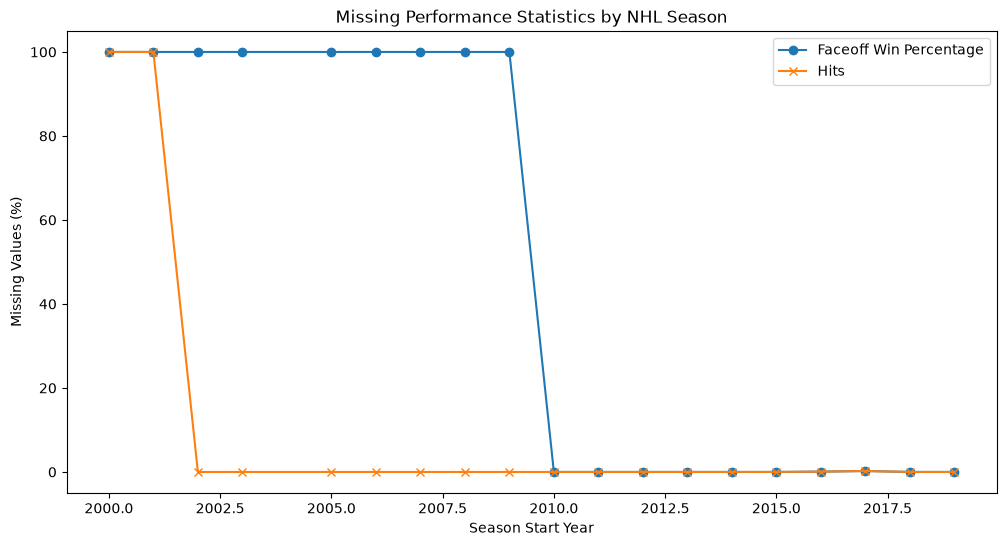

In [17]:
# Investigate missing-value percentages across NHL seasons
plt.figure(figsize=(12, 6))

plt.plot(
    missing_by_season.index,
    missing_by_season["home_faceOffWinPercentage"],
    marker="o",
    label="Faceoff Win Percentage"
)

plt.plot(
    missing_by_season.index,
    missing_by_season["home_hits"],
    marker="x",
    label="Hits"
)

plt.title("Missing Performance Statistics by NHL Season")
plt.xlabel("Season Start Year")
plt.ylabel("Missing Values (%)")
plt.legend()

In [18]:
# Investigate missing-value percentages by game type
missing_by_game_type = (
    game_stats_clean[missing_stats]
    .isna()
    .groupby(game_stats_clean["game_type"])
    .mean() * 100
)

missing_by_game_type.round(2).T

game_type,Playoffs,Regular Season
home_faceOffWinPercentage,0.43,48.57
home_hits,0.43,10.79
home_giveaways,0.43,10.79
home_takeaways,0.43,10.79
home_blocked,0.43,10.79
home_goals,0.43,0.00
home_shots,0.43,0.00
home_pim,0.43,0.00
home_powerPlayOpportunities,0.43,0.00
home_powerPlayGoals,0.43,0.00


In this section, I identified systematic historical missingness in faceoff win percentages and several defensive and physical performance statistics.

**3.4 Data Consistency and Validation**

In [19]:
# Examining the remaining settlement categories
display(game_stats_clean["home_settled_in"].value_counts())
display(game_stats_clean["away_settled_in"].value_counts())

# Check for identical settlement columns
print("Identical settlement columns:",
      game_stats_clean["home_settled_in"].equals(
          game_stats_clean["away_settled_in"]
      ))

home_settled_in
REG    18153
OT      5563
tbc       14
Name: count, dtype: int64

away_settled_in
REG    18153
OT      5563
tbc       14
Name: count, dtype: int64

Identical settlement columns: True


In [20]:
# Check games with the undocumented settlement category
tbc_games = game_stats_clean[
    game_stats_clean["home_settled_in"] == "tbc"
]

# These games are all playoff games, so they may be tbc because the series has been concluded
display(tbc_games[[
    "game_id",
    "season",
    "game_type",
    "date_time_GMT",
    "home_team",
    "away_team",
    "home_won",
    "away_won",
    "home_goals",
    "away_goals",
    "home_shots",
    "away_shots"
]].sort_values("game_id"))

,game_id,season,game_type,date_time_GMT,home_team,away_team,home_won,away_won,home_goals,away_goals,home_shots,away_shots
20671,2016030137,2016,Playoffs,2017-04-25 23:30:00+00:00,Washington Capitals,Toronto Maple Leafs,False,False,0.0,0.0,0.0,0.0
20830,2016030155,2016,Playoffs,2017-04-23 00:00:00+00:00,Chicago Blackhawks,Nashville Predators,False,False,0.0,0.0,0.0,0.0
20537,2016030175,2016,Playoffs,2017-04-22 02:00:00+00:00,Anaheim Ducks,Calgary Flames,False,False,0.0,0.0,0.0,0.0
20885,2016030217,2016,Playoffs,2017-05-11 23:30:00+00:00,Ottawa Senators,NY Rangers Rangers,False,False,NaN,NaN,NaN,NaN
20750,2016030327,2016,Playoffs,2017-05-25 01:00:00+00:00,Anaheim Ducks,Nashville Predators,False,False,0.0,0.0,0.0,0.0
20768,2016030417,2016,Playoffs,2017-06-15 00:00:00+00:00,Pittsburgh Penguins,Nashville Predators,False,False,0.0,0.0,0.0,0.0
20477,2017030175,2017,Playoffs,2018-04-20 02:00:00+00:00,Vegas Golden Knights,Los Angeles Kings,False,False,0.0,0.0,0.0,0.0
20452,2017030185,2017,Playoffs,2018-04-21 02:30:00+00:00,Anaheim Ducks,San Jose Sharks,False,False,NaN,NaN,NaN,NaN
20527,2017030227,2017,Playoffs,2018-05-09 23:30:00+00:00,Washington Capitals,Pittsburgh Penguins,False,False,0.0,0.0,0.0,0.0
20447,2017030247,2017,Playoffs,2018-05-09 01:00:00+00:00,Vegas Golden Knights,San Jose Sharks,False,False,0.0,0.0,0.0,0.0


In [21]:
# These are all playoff games, I want to check whether all these series were concluded at this point
for game_id in tbc_games["game_id"]:
    earlier_games = game_stats_clean[
        (game_stats_clean["game_id"].str[:-1] == game_id[:-1]) &
        (game_stats_clean["game_id"] < game_id)
    ]

    winners = pd.concat([
        earlier_games.loc[earlier_games["home_won"], "home_team"],
        earlier_games.loc[earlier_games["away_won"], "away_team"]
    ])

    print(game_id, winners.value_counts().max() == 4)

2017030247 True
2017030185 True
2017030175 True
2017030326 True
2017030327 True
2017030416 True
2017030417 True
2017030227 True
2016030175 True
2016030137 True
2016030327 True
2016030417 True
2016030155 True
2016030217 True


In [22]:
# Remove all these games, since they were never played due to the series having concluded
game_stats_clean = game_stats_clean[
    ~game_stats_clean["game_id"].isin(tbc_games["game_id"])
].copy()

print(game_stats_clean.shape)
display(game_stats_clean["game_type"].value_counts())

(23716, 32)


game_type
Regular Season    22794
Playoffs            922
Name: count, dtype: int64

In [23]:
# Examine home and away outcomes
display(pd.crosstab(
    game_stats_clean["home_won"],
    game_stats_clean["away_won"]
))

# Investigate games where neither team won
tied_games = game_stats_clean[
    (~game_stats_clean["home_won"]) &
    (~game_stats_clean["away_won"])
]

display(tied_games["season"].value_counts().sort_index())

print("All scores equal:",
      (tied_games["home_goals"] == tied_games["away_goals"]).all())

away_won,False,True
home_won,,
False,628,10408
True,12680,0


season
2000    152
2001    149
2002    157
2003    170
Name: count, dtype: int64

All scores equal: True


In [24]:
# Check if winning teams scored fewer goals than their opponents
for side, opponent in [("home", "away"), ("away", "home")]:
    print(side, "winners with fewer goals:",
          (game_stats_clean[side + "_won"] &
           (game_stats_clean[side + "_goals"] <
            game_stats_clean[opponent + "_goals"])).sum())

# Investigate score ties with a recorded winner
equal_score_winners = game_stats_clean[
    (game_stats_clean["home_goals"] == game_stats_clean["away_goals"]) &
    (game_stats_clean["home_won"] | game_stats_clean["away_won"])
]

display(equal_score_winners["home_settled_in"].value_counts())

home winners with fewer goals: 0
away winners with fewer goals: 0


home_settled_in
OT    2067
Name: count, dtype: int64

In [25]:
# Check for any invalid numerical statistics
print("Negative values:", (game_stats_clean.select_dtypes(include="number") < 0).sum().sum())

for side in ["home", "away"]:
    print(side, "goals exceeding shots:",
          (game_stats_clean[side + "_goals"] > game_stats_clean[side + "_shots"]).sum())

    print(side, "zero shots:",
          (game_stats_clean[side + "_shots"] == 0).sum())

Negative values: 0
home goals exceeding shots: 0
home zero shots: 0
away goals exceeding shots: 0
away zero shots: 0


In [26]:
# Inspect unique team names
team_names = pd.concat([game_stats_clean["home_team"], 
                        game_stats_clean["away_team"]]).unique()

print("Number of teams:", len(team_names))
print(sorted(team_names))

Number of teams: 33
['Anaheim Ducks', 'Arizona Coyotes', 'Atlanta Thrashers', 'Boston Bruins', 'Buffalo Sabres', 'Calgary Flames', 'Carolina Hurricanes', 'Chicago Blackhawks', 'Colorado Avalanche', 'Columbus Blue Jackets', 'Dallas Stars', 'Detroit Red Wings', 'Edmonton Oilers', 'Florida Panthers', 'Los Angeles Kings', 'Minnesota Wild', 'Montreal Canadiens', 'NY Islanders Islanders', 'NY Rangers Rangers', 'Nashville Predators', 'New Jersey Devils', 'Ottawa Senators', 'Philadelphia Flyers', 'Phoenix Coyotes', 'Pittsburgh Penguins', 'San Jose Sharks', 'St Louis Blues', 'Tampa Bay Lightning', 'Toronto Maple Leafs', 'Vancouver Canucks', 'Vegas Golden Knights', 'Washington Capitals', 'Winnipeg Jets']


In [27]:
# Correct incorrectly recorded shot totals that were spotted in 8.2
game_stats_clean.loc[game_stats_clean["game_id"] == "2005021179", "home_shots"] = 34
game_stats_clean.loc[game_stats_clean["game_id"] == "2005021179", "away_shots"] = 25

# Verify corrected values
display(game_stats_clean.loc[game_stats_clean["game_id"] == "2005021179"])

,game_id,date_time_GMT,home_team,away_team,home_won,home_settled_in,home_head_coach,home_goals,home_shots,home_hits,...,away_hits,away_pim,away_powerPlayOpportunities,away_powerPlayGoals,away_faceOffWinPercentage,away_giveaways,away_takeaways,away_blocked,season,game_type
17412,2005021179,2006-04-12 01:00:00+00:00,Colorado Avalanche,Phoenix Coyotes,True,REG,Joel Quenneville,6.0,34.0,4.0,...,17.0,23.0,8.0,1.0,NaN,4.0,7.0,10.0,2005,Regular Season


This section was the most crucial. I removed 14 unplayed playoff games after confirming their respective series had already concluded. I retained 628 legitimate draws and 2,067 equal-score games with recorded winners. The numerical validation checks also showed no violations of the tested conditions.

During feature engineering in Section 8.2, a game between the Colorado Avalanche and Phoenix Coyotes (game ID: 2005021179) was identified in which both teams had a shooting percentage of 100%. Consulting the ESPN box score confirmed that the recorded shot totals were wrong, and the shots taken were corrected from 6 and 4 to 34 and 25, respectively. Faceoff percentages were also available from ESPN but I left them unchanged to maintain consistency with the treatment of historical missing values.

**3.5 Handling Missing Values**

In [28]:
# Display missing values after removing unplayed playoff games
remaining_missing = pd.DataFrame({
    "Missing Values": game_stats_clean.isna().sum(),
    "Missing Percentage": (game_stats_clean.isna().mean() * 100).round(2)
})

# Display any variables with remaining missing values
display(remaining_missing[remaining_missing["Missing Values"] > 0])

,Missing Values,Missing Percentage
home_hits,2460,10.37
home_faceOffWinPercentage,11070,46.68
home_giveaways,2460,10.37
home_takeaways,2460,10.37
home_blocked,2460,10.37
away_hits,2460,10.37
away_faceOffWinPercentage,11070,46.68
away_giveaways,2460,10.37
away_takeaways,2460,10.37
away_blocked,2460,10.37


I retained historical missing values to avoid unnecessary data loss and misleading imputation. Missing observations will be excluded depending on the analysis being conducted, and the missing-value analysis conducted in this section will be used to inform those decisions in future sections.

**3.6 Column Names and Redundancy**

In [29]:
# New column names
column_mapping = {
    "date_time_GMT": "date_time_utc",
    "home_powerPlayOpportunities": "home_power_play_opportunities",
    "away_powerPlayOpportunities": "away_power_play_opportunities",
    "home_powerPlayGoals": "home_power_play_goals",
    "away_powerPlayGoals": "away_power_play_goals",
    "home_faceOffWinPercentage": "home_faceoff_win_percentage",
    "away_faceOffWinPercentage": "away_faceoff_win_percentage",
    "home_pim": "home_penalty_minutes",
    "away_pim": "away_penalty_minutes",
    "home_blocked": "home_blocked_shots",
    "away_blocked": "away_blocked_shots"
}

game_stats_clean = game_stats_clean.rename(columns=column_mapping)

In [30]:
# Removing the redundant settlement column
game_stats_clean = game_stats_clean.drop(columns=["away_settled_in"])

game_stats_clean = game_stats_clean.rename(
    columns={"home_settled_in": "settled_in"}
)

In [31]:
# Fixing team naming inconsistencies
team_mapping = {
    "NY Islanders Islanders": "New York Islanders",
    "NY Rangers Rangers": "New York Rangers",
    "St Louis Blues": "St. Louis Blues"
}

for side in ["home", "away"]:
    game_stats_clean[side + "_team"] = game_stats_clean[side + "_team"].replace(team_mapping)

# Verify cleaned dataset dimensions and column names
print("Dataset dimensions:", game_stats_clean.shape)
display(game_stats_clean.columns)

Dataset dimensions: (23716, 31)


Index(['game_id', 'date_time_utc', 'home_team', 'away_team', 'home_won',
       'settled_in', 'home_head_coach', 'home_goals', 'home_shots',
       'home_hits', 'home_penalty_minutes', 'home_power_play_opportunities',
       'home_power_play_goals', 'home_faceoff_win_percentage',
       'home_giveaways', 'home_takeaways', 'home_blocked_shots', 'away_won',
       'away_head_coach', 'away_goals', 'away_shots', 'away_hits',
       'away_penalty_minutes', 'away_power_play_opportunities',
       'away_power_play_goals', 'away_faceoff_win_percentage',
       'away_giveaways', 'away_takeaways', 'away_blocked_shots', 'season',
       'game_type'],
      dtype='str')

Here, I standardized the column names, removed the redundant settlement column, and corrected the team naming inconsistencies while preserving their historical team identities.

**3.7 Final Cleaned Dataset**

In [32]:
# Check the final cleaned dataset
print("Original dataset dimensions:", game_stats.shape)
print("Cleaned dataset dimensions:", game_stats_clean.shape)
print("Rows removed:", len(game_stats) - len(game_stats_clean))
print("Duplicate game IDs:", game_stats_clean["game_id"].duplicated().sum())

# Check game types and team names
display(game_stats_clean["game_type"].value_counts())

display(sorted(pd.concat([
    game_stats_clean["home_team"],
    game_stats_clean["away_team"]
]).unique()))

# Display the cleaned dataset
game_stats_clean.head()

Original dataset dimensions: (23735, 30)
Cleaned dataset dimensions: (23716, 31)
Rows removed: 19
Duplicate game IDs: 0


game_type
Regular Season    22794
Playoffs            922
Name: count, dtype: int64

['Anaheim Ducks',
 'Arizona Coyotes',
 'Atlanta Thrashers',
 'Boston Bruins',
 'Buffalo Sabres',
 'Calgary Flames',
 'Carolina Hurricanes',
 'Chicago Blackhawks',
 'Colorado Avalanche',
 'Columbus Blue Jackets',
 'Dallas Stars',
 'Detroit Red Wings',
 'Edmonton Oilers',
 'Florida Panthers',
 'Los Angeles Kings',
 'Minnesota Wild',
 'Montreal Canadiens',
 'Nashville Predators',
 'New Jersey Devils',
 'New York Islanders',
 'New York Rangers',
 'Ottawa Senators',
 'Philadelphia Flyers',
 'Phoenix Coyotes',
 'Pittsburgh Penguins',
 'San Jose Sharks',
 'St. Louis Blues',
 'Tampa Bay Lightning',
 'Toronto Maple Leafs',
 'Vancouver Canucks',
 'Vegas Golden Knights',
 'Washington Capitals',
 'Winnipeg Jets']

,game_id,date_time_utc,home_team,away_team,home_won,settled_in,home_head_coach,home_goals,home_shots,home_hits,...,away_hits,away_penalty_minutes,away_power_play_opportunities,away_power_play_goals,away_faceoff_win_percentage,away_giveaways,away_takeaways,away_blocked_shots,season,game_type
0,2016020045,2016-10-19 00:30:00+00:00,Chicago Blackhawks,Philadelphia Flyers,True,REG,Joel Quenneville,7.0,28.0,20.0,...,30.0,6.0,4.0,2.0,50.9,12.0,9.0,11.0,2016,Regular Season
1,2017020812,2018-02-07 00:00:00+00:00,Buffalo Sabres,Anaheim Ducks,False,OT,Phil Housley,3.0,33.0,17.0,...,16.0,6.0,3.0,1.0,43.8,7.0,4.0,14.0,2017,Regular Season
2,2015020314,2015-11-24 01:00:00+00:00,Winnipeg Jets,Colorado Avalanche,False,REG,Paul Maurice,1.0,21.0,22.0,...,17.0,9.0,3.0,1.0,45.7,13.0,5.0,20.0,2015,Regular Season
3,2015020849,2016-02-17 00:00:00+00:00,Carolina Hurricanes,Winnipeg Jets,True,REG,Bill Peters,2.0,29.0,16.0,...,21.0,10.0,4.0,0.0,31.4,4.0,14.0,16.0,2015,Regular Season
4,2017020586,2017-12-30 03:00:00+00:00,Anaheim Ducks,Calgary Flames,True,REG,Randy Carlyle,2.0,41.0,15.0,...,20.0,19.0,3.0,0.0,54.7,10.0,4.0,7.0,2017,Regular Season


After cleaning, 23,716 observations and 31 variables were retained for my analysis. This represents 99.92% of the original observations, demonstrating that the cleaning process preserved nearly all available games. Further filtering may be required depending on which variables are needed for subsequent analysis.

## 4. Descriptive Statistics

**4.1 Numerical Summary Statistics**

In [33]:
# Isolate numerical performance variables, excluding the season identifier
numerical_stats = game_stats_clean.select_dtypes(include="number").drop(columns=["season"])

# Display descriptive statistics for numerical performance variables
display(numerical_stats.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
home_goals,23716.0,2.90,1.68,0.0,2.0,3.0,4.0,12.0
home_shots,23716.0,30.67,6.88,9.0,26.0,30.0,35.0,88.0
home_hits,21256.0,21.80,9.18,0.0,16.0,21.0,27.0,80.0
home_penalty_minutes,23716.0,11.75,9.05,0.0,6.0,10.0,15.0,213.0
home_power_play_opportunities,23716.0,3.94,1.94,0.0,3.0,4.0,5.0,15.0
home_power_play_goals,23716.0,0.73,0.85,0.0,0.0,1.0,1.0,6.0
home_faceoff_win_percentage,12646.0,51.61,7.02,24.1,46.9,51.7,56.4,79.2
home_giveaways,21256.0,10.02,5.72,0.0,6.0,9.0,13.0,52.0
home_takeaways,21256.0,7.56,4.41,0.0,5.0,7.0,10.0,40.0
home_blocked_shots,21256.0,12.93,5.55,0.0,9.0,13.0,16.0,40.0


Home teams average more goals (2.90 vs. 2.62) and more shots on goal (30.67 vs. 28.90) than away teams, showing some evidence of home advantage. They also average more power-play opportunities and power-play goals, while recording fewer penalty minutes. Away teams average slightly more blocked shots (13.51 vs. 12.93), which may suggest that they face greater offensive pressure from the home teams. Some variables have high maximum values, such as shots (88) and penalty minutes (213), which warrant further examination. Observation counts vary between 12,646 and 23,716 due to historical missingness identified in Section 3. 

**4.2 Categorical Summary Statistics**

In [34]:
# Select most pertinent categorical and Boolean variables
categorical_stats = game_stats_clean[[
    "home_team", "away_team", "home_won",
    "away_won", "settled_in", "game_type"
]]

# Display categorical summary statistics
display(categorical_stats.describe(include="all").T)

,count,unique,top,freq
home_team,23716,33,Boston Bruins,821
away_team,23716,33,Boston Bruins,812
home_won,23716,2,True,12680
away_won,23716,2,False,13308
settled_in,23716,2,REG,18153
game_type,23716,2,Regular Season,22794


In [35]:
# Display frequencies and percentages for the selected categorical variables
for column in ["home_won", "away_won", "settled_in", "game_type"]:
    print(column)

    display(pd.DataFrame({
        "Count": game_stats_clean[column].value_counts(),
        "Percentage": (game_stats_clean[column].value_counts(normalize=True) * 100).round(2)
    }))

home_won


,Count,Percentage
home_won,,
True,12680,53.47
False,11036,46.53


away_won


,Count,Percentage
away_won,,
False,13308,56.11
True,10408,43.89


settled_in


,Count,Percentage
settled_in,,
REG,18153,76.54
OT,5563,23.46


game_type


,Count,Percentage
game_type,,
Regular Season,22794,96.11
Playoffs,922,3.89


This dataset contains 33 distinct historical team names. The Boston Bruins are the most frequently represented team in both home and away observations. There is additional evidence of home advantage, as home teams won 53.47% of their games, compared to 43.89% for away teams, with 2.65% ending in draws. 76.54% of the games ended in regulation time and 23.46% were classified overtime, a category that appears to include shootouts. Regular-season games account for 96.11% of observations, and compared to only 3.89% for playoff games (All-Star games have been removed).

**4.3 Initial Observations**

These descriptive statistics have already provided preliminary evidence of home advantage in both offensive performance and game outcomes. Additional analysis is needed to determine which offensive, defensive, and special teams statistics are most strongly associated with winning in regular-season and playoff games. The historical missingness and the unequal representation of regular-season and playoff games must be considered in upcoming sections.

## 5. Numerical Data Visualizations

**5.1 Offensive Performance**

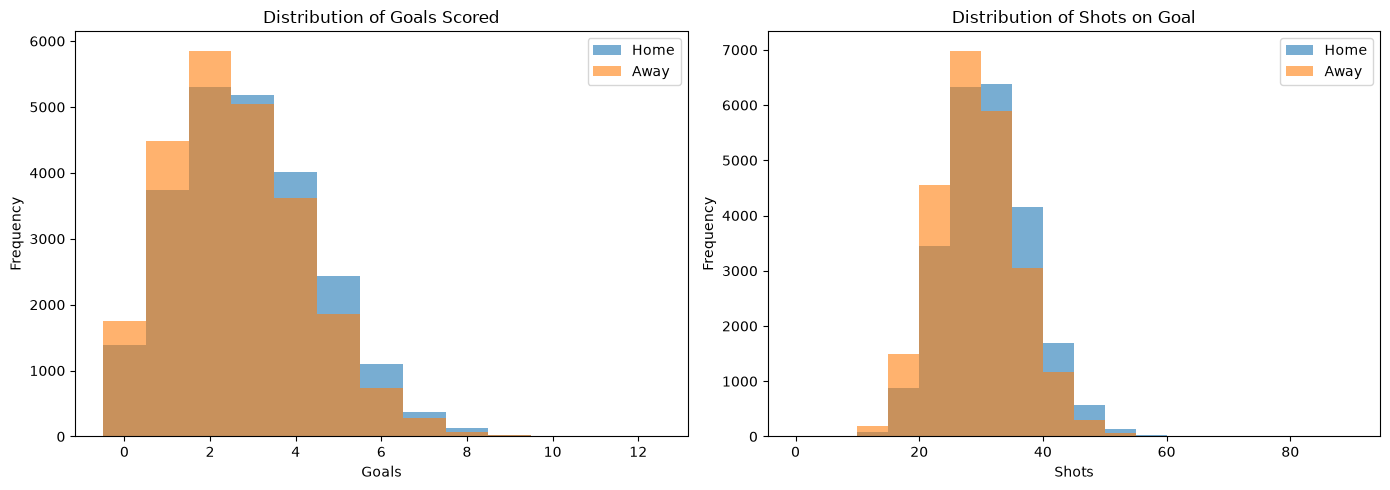

In [36]:
# Visualize distribution of goals and shots for home and away teams
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Goals
bins_goals = np.arange(0, numerical_stats[["home_goals", "away_goals"]].max().max() + 2) - 0.5

ax[0].hist(game_stats_clean["home_goals"], bins=bins_goals, alpha=0.6, label="Home")
ax[0].hist(game_stats_clean["away_goals"], bins=bins_goals, alpha=0.6, label="Away")
ax[0].set_title("Distribution of Goals Scored")
ax[0].set_xlabel("Goals")
ax[0].set_ylabel("Frequency")
ax[0].legend()

# Shots
bins_shots = np.arange(0, numerical_stats[["home_shots", "away_shots"]].max().max() + 5, 5)

ax[1].hist(game_stats_clean["home_shots"], bins=bins_shots, alpha=0.6, label="Home")
ax[1].hist(game_stats_clean["away_shots"], bins=bins_shots, alpha=0.6, label="Away")
ax[1].set_title("Distribution of Shots on Goal")
ax[1].set_xlabel("Shots")
ax[1].set_ylabel("Frequency")
ax[1].legend()

plt.tight_layout()
plt.show()

The distribution of goals scored is right-skewed, with most observations are concentrated between one and four goals. Two is the most frequent number of goals for both home and away teams. The shots on goal histogram is more bell-shaped then the distribution of goals, with a slight right skew. Both histograms show more shots and goals respectively for home teams so they show home advantage. However, there is substantial overlap between home and away distributions.

**5.2 Defensive and Special Teams Performance**

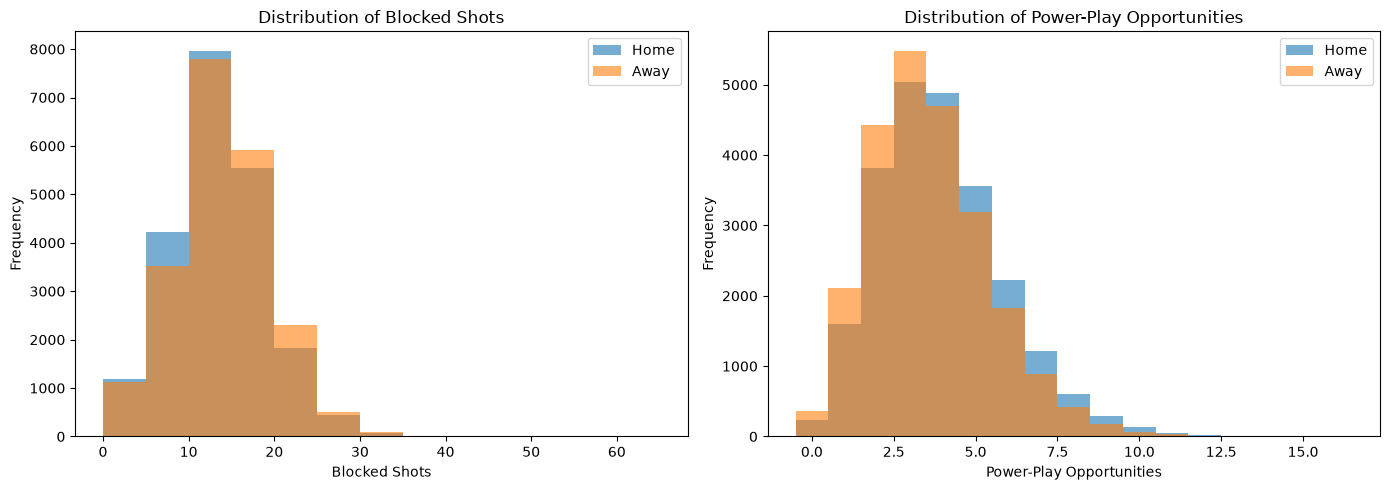

In [37]:
# Visualize defensive and special teams data
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Blocked shots
bins_blocked = np.arange(0, numerical_stats[["home_blocked_shots", "away_blocked_shots"]].max().max() + 5, 5)

ax[0].hist(game_stats_clean["home_blocked_shots"].dropna(), bins=bins_blocked, alpha=0.6, label="Home")
ax[0].hist(game_stats_clean["away_blocked_shots"].dropna(), bins=bins_blocked, alpha=0.6, label="Away")
ax[0].set_title("Distribution of Blocked Shots")
ax[0].set_xlabel("Blocked Shots")
ax[0].set_ylabel("Frequency")
ax[0].legend()

# Power-play opportunities
bins_pp = np.arange(0, numerical_stats[["home_power_play_opportunities", "away_power_play_opportunities"]].max().max() + 2) - 0.5

ax[1].hist(game_stats_clean["home_power_play_opportunities"], bins=bins_pp, alpha=0.6, label="Home")
ax[1].hist(game_stats_clean["away_power_play_opportunities"], bins=bins_pp, alpha=0.6, label="Away")
ax[1].set_title("Distribution of Power-Play Opportunities")
ax[1].set_xlabel("Power-Play Opportunities")
ax[1].set_ylabel("Frequency")
ax[1].legend()

plt.tight_layout()
plt.show()

The histogram of blocked shot shows a right-skewed distribution with the most frequent interval being the 10-14 range for both home and away teams. Away teams tend to record more blocked shots, which may suggest that they face greater offensive pressure rather than just being better defensively. 

Power-play opportunities have a right-skewed distribution with home teams tending to receive more opportunities. On the other hand, receiving more opportunities does not necessarily indicate greater power-play efficiency.

**5.3 Variability and Outliers**

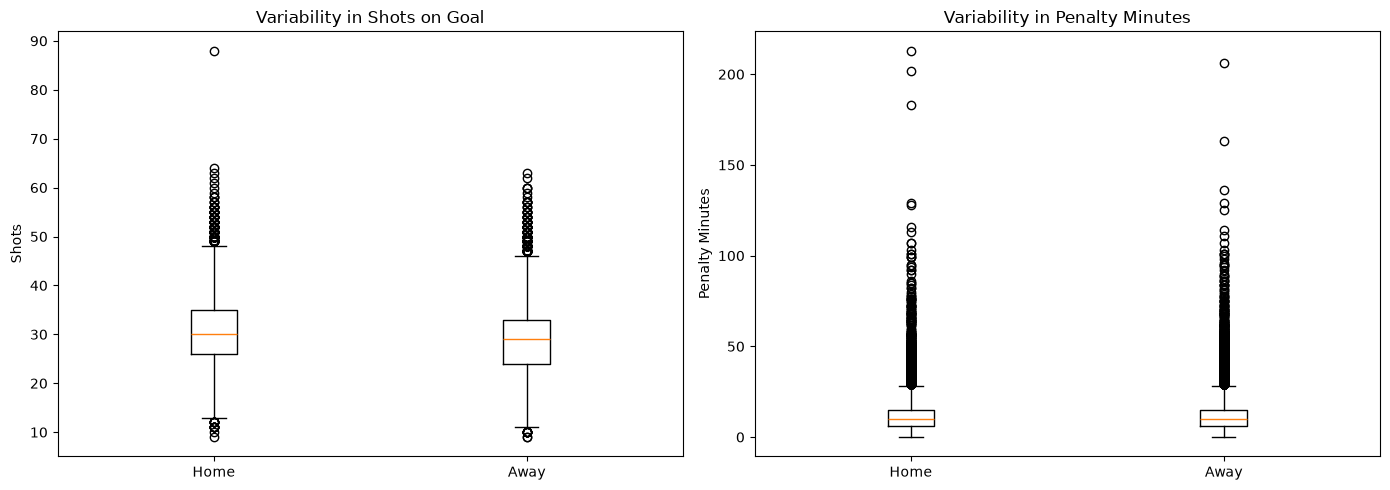

,Median,Q1,Q3,IQR
home_shots,30.0,26.0,35.0,9.0
away_shots,29.0,24.0,33.0,9.0
home_penalty_minutes,10.0,6.0,15.0,9.0
away_penalty_minutes,10.0,6.0,15.0,9.0


In [38]:
# Visualize variability and outliers in shots and penalty minutes
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Shots on goal
ax[0].boxplot([
    game_stats_clean["home_shots"],
    game_stats_clean["away_shots"]
])

ax[0].set_xticks([1, 2], ["Home", "Away"])
ax[0].set_title("Variability in Shots on Goal")
ax[0].set_ylabel("Shots")

# Penalty minutes
ax[1].boxplot([
    game_stats_clean["home_penalty_minutes"],
    game_stats_clean["away_penalty_minutes"]
])

ax[1].set_xticks([1, 2], ["Home", "Away"])
ax[1].set_title("Variability in Penalty Minutes")
ax[1].set_ylabel("Penalty Minutes")

plt.tight_layout()
plt.show()

# Calculate median and interquartile range (IQR)
boxplot_stats = numerical_stats[[
    "home_shots", "away_shots",
    "home_penalty_minutes", "away_penalty_minutes"
]]

summary = pd.DataFrame({
    "Median": boxplot_stats.median(),
    "Q1": boxplot_stats.quantile(0.25),
    "Q3": boxplot_stats.quantile(0.75),
    "IQR": boxplot_stats.quantile(0.75) - boxplot_stats.quantile(0.25)
})

display(summary)

Home teams have a marginally higher median number of shots on goal (30 vs. 29), they both have identical interquartile ranges. Both home and away teams have a median of 10 penalty minutes and identical interquartile ranges. This measure has numerous upper outliers though, with a substantial right skew. Extreme values are noticeable for home shots (88) and penalty minutes (213 for home teams and 206 for away teams). These observations are retained because a statistical outlier does not necessarily indicate a data error.

## 6. Categorical Data Analysis

**6.1 Game Outcomes and Home Advantage**

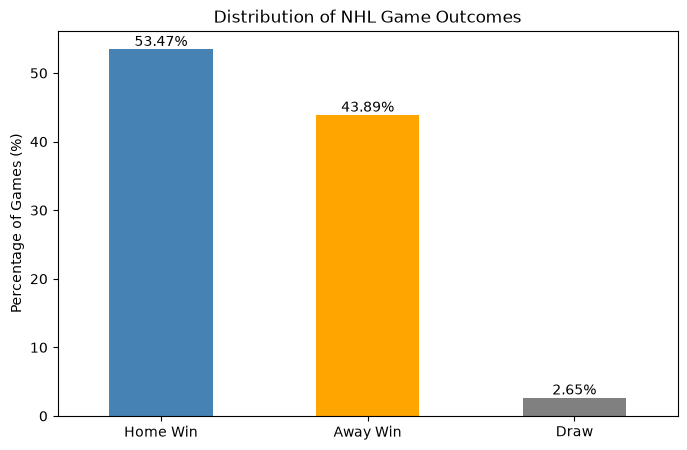

In [39]:
# Calculate game outcome percentages
outcomes = pd.Series({
    "Home Win": game_stats_clean["home_won"].mean() * 100,
    "Away Win": game_stats_clean["away_won"].mean() * 100,
    "Draw": (~game_stats_clean["home_won"] & ~game_stats_clean["away_won"]).mean() * 100
})

# Visualize game outcome percentages
ax = outcomes.plot(kind="bar", figsize=(8, 5), color=["steelblue", "orange", "grey"])

ax.set_title("Distribution of NHL Game Outcomes")
ax.set_ylabel("Percentage of Games (%)")
ax.set_xticklabels(outcomes.index, rotation=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%")

plt.show()

Home teams won 53.47% of their games, compared to 43.89% for away teams. This is a difference of 9.58 percentage points. This is consistent with the offensive performance distributions examined in Section 5. Historical draws account for approximately 2.65% of games. Further grouped analysis will help us determine how home advantage varies across teams and game types.

**6.2 Game Settlement and Game Types**

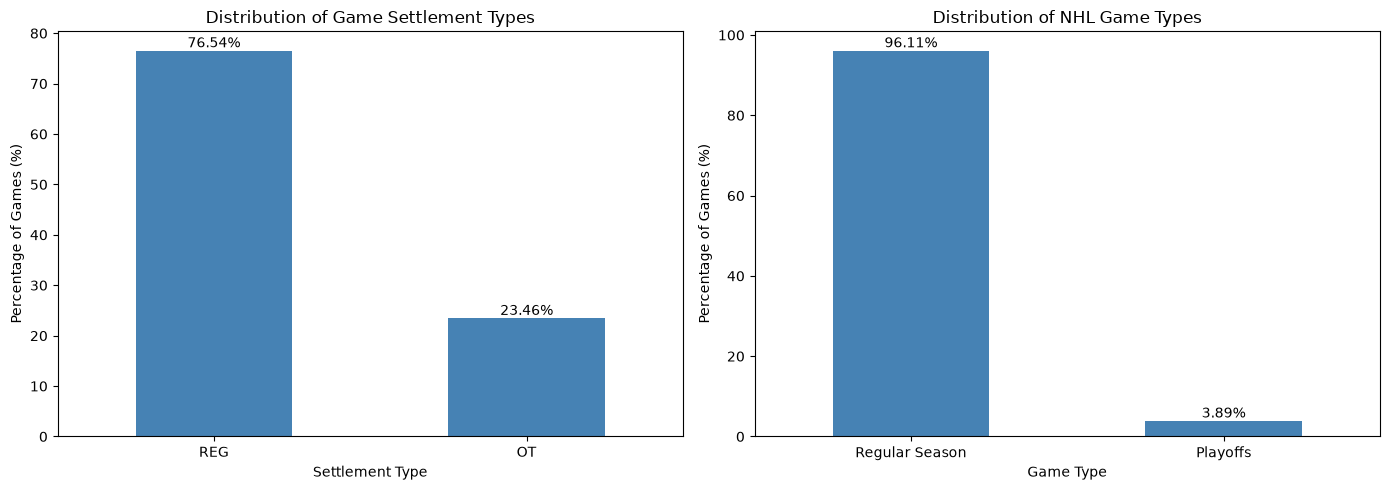

In [40]:
# Calculate percentage distributions
settlement = game_stats_clean["settled_in"].value_counts(normalize=True) * 100
game_types = game_stats_clean["game_type"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Game settlement
settlement.plot(kind="bar", ax=ax[0], color="steelblue", rot=0)
ax[0].set_title("Distribution of Game Settlement Types")
ax[0].set_ylabel("Percentage of Games (%)")
ax[0].set_xlabel("Settlement Type")
ax[0].bar_label(ax[0].containers[0], fmt="%.2f%%")

# Game types
game_types.plot(kind="bar", ax=ax[1], color="steelblue", rot=0)
ax[1].set_title("Distribution of NHL Game Types")
ax[1].set_ylabel("Percentage of Games (%)")
ax[1].set_xlabel("Game Type")
ax[1].bar_label(ax[1].containers[0], fmt="%.2f%%")

plt.tight_layout()
plt.show()

76.54% of games ended in regulation time, while 23.46% were classified as overtime, which appears to includes shootouts. Regular-season games account for 96.11% of observations, with only 3.89% for playoff games. The difference in sample sizes and limited coverage for playoff games will need to be considered when we begin to analyze regular-season performance and playoff success. 

## 7. Grouped Analysis

**7.1 Home Advantage by Team**

In [41]:
# First we want to select only regular season games
regular_season = game_stats_clean[game_stats_clean["game_type"] == "Regular Season"]

# Calculate home and away win percentages by team
home_stats = regular_season.groupby("home_team")["home_won"].agg(["count", "mean"])
away_stats = regular_season.groupby("away_team")["away_won"].agg(["count", "mean"])

# Rename columns
home_stats.columns = ["Home Games", "Home Win %"]
away_stats.columns = ["Away Games", "Away Win %"]

# Combine home and away statistics
home_advantage = home_stats.join(away_stats)

home_advantage["Home Win %"] *= 100
home_advantage["Away Win %"] *= 100

# Calculate home advantage in percentage points
home_advantage["Home Advantage"] = (
    home_advantage["Home Win %"] - home_advantage["Away Win %"]
)
home_advantage = home_advantage.sort_values("Home Advantage", ascending=False)

display(home_advantage.round(2))

,Home Games,Home Win %,Away Games,Away Win %,Home Advantage
home_team,,,,,
Tampa Bay Lightning,755,56.82,757,42.93,13.89
Anaheim Ducks,757,56.67,756,43.52,13.15
Vegas Golden Knights,119,63.03,116,50.00,13.03
Columbus Blue Jackets,757,50.07,755,37.22,12.85
Nashville Predators,756,56.75,755,44.50,12.24
Minnesota Wild,756,53.97,755,41.85,12.11
Pittsburgh Penguins,756,57.94,755,46.23,11.71
St. Louis Blues,756,57.41,757,45.71,11.70
Washington Capitals,754,58.09,757,46.76,11.33


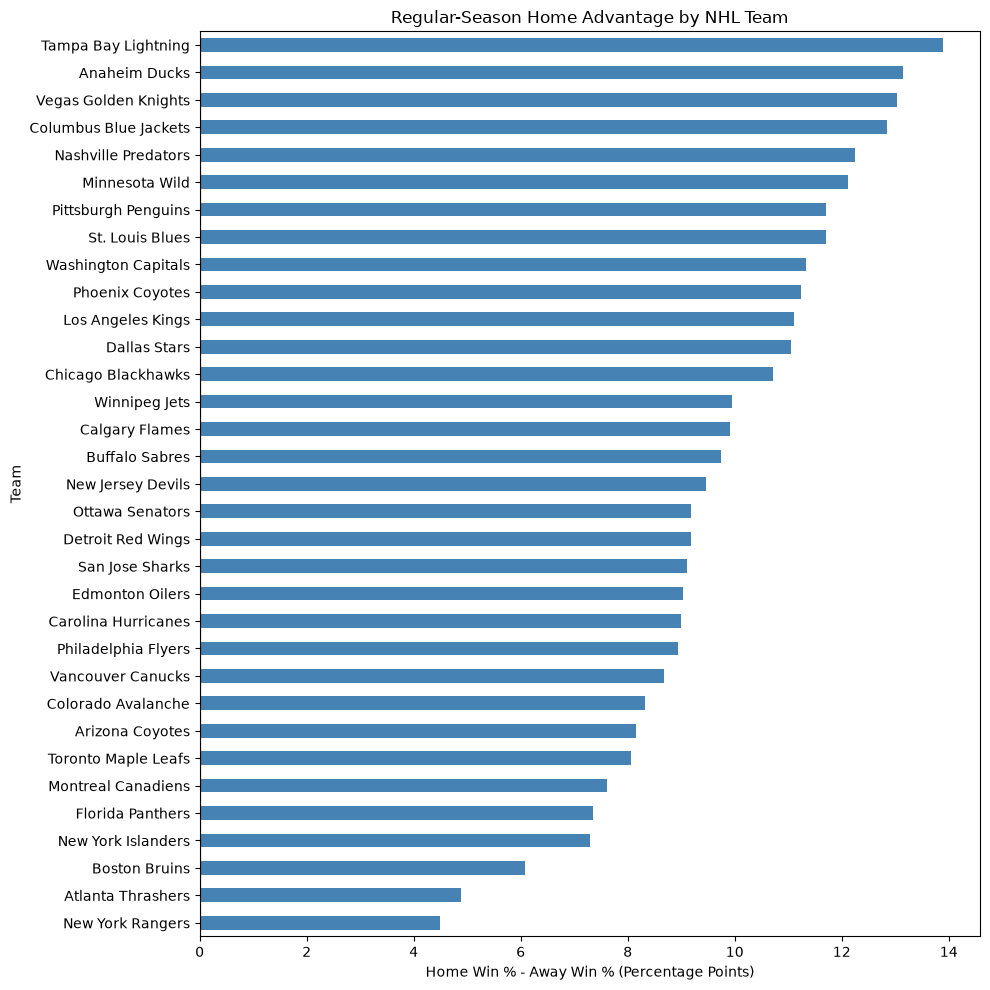

In [42]:
# Horizontal Bar chart for home advantage by team
home_advantage["Home Advantage"].sort_values().plot(
    kind="barh", figsize=(10, 10), color="steelblue"
)

plt.title("Regular-Season Home Advantage by NHL Team")
plt.xlabel("Home Win % - Away Win % (Percentage Points)")
plt.ylabel("Team")
plt.axvline(0, color="black")
plt.tight_layout()
plt.show()

All 33 teams show a higher winning percentage at home then away, which strongly supports the existence of home advantage in the NHL. The Tampa Bay Lightning have the largest home advantage (13.89 percentage points) and the New York Rangers have the smallest (4.5 percentage points). Some expansion teams like the Vegas Golden Knights, created in 2016, should have their sample size taken into account.

**7.2 Regular-Season vs. Playoff Performance**

In [43]:
# Select seasons with both regular-season and playoff data
comparable_games = game_stats_clean[game_stats_clean["season"] >= 2010].copy()

# Calculate combined game statistics
comparable_games["total_goals"] = comparable_games["home_goals"] + comparable_games["away_goals"]
comparable_games["total_shots"] = comparable_games["home_shots"] + comparable_games["away_shots"]
comparable_games["total_penalty_minutes"] = comparable_games["home_penalty_minutes"] + comparable_games["away_penalty_minutes"]

# Calculate grouped averages by game type
game_type_stats = comparable_games.groupby("game_type")[[
    "home_won", "away_won", "total_goals",
    "total_shots", "total_penalty_minutes"
]].mean()

# Convert win proportions to percentages and include game counts
game_type_stats[["home_won", "away_won"]] *= 100
game_type_stats["Games"] = comparable_games.groupby("game_type").size()

display(game_type_stats.round(2))

,home_won,away_won,total_goals,total_shots,total_penalty_minutes,Games
game_type,,,,,,
Playoffs,53.15,46.85,5.35,61.90,22.41,922
Regular Season,54.37,45.63,5.54,60.91,19.87,11724


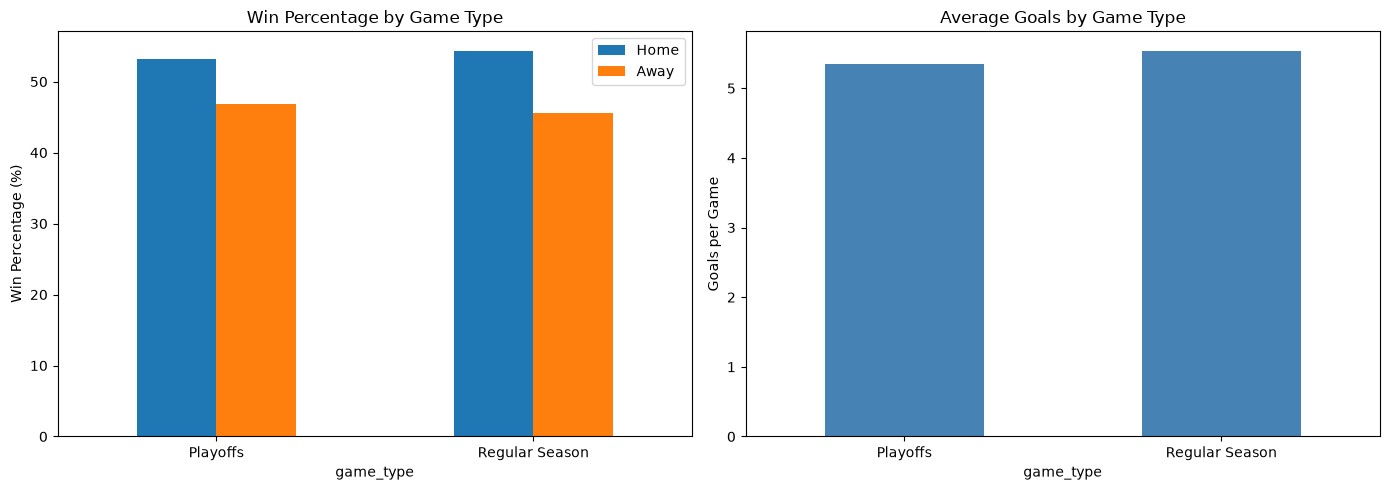

In [44]:
# Compare game outcomes and scoring by game type
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Home and away win percentages
game_type_stats[["home_won", "away_won"]].plot(kind="bar", ax=ax[0], rot=0)
ax[0].set_title("Win Percentage by Game Type")
ax[0].set_ylabel("Win Percentage (%)")
ax[0].legend(["Home", "Away"])

# Average goals per game
game_type_stats["total_goals"].plot(kind="bar", ax=ax[1], rot=0, color="steelblue")
ax[1].set_title("Average Goals by Game Type")
ax[1].set_ylabel("Goals per Game")

plt.tight_layout()
plt.show()

Home teams win 54.37% of regular-season games compared to 53.15% of playoff games, suggesting a slightly weaker home advantage during the playoffs. Playoff games also have fewer goals on average (5.35 vs. 5.54), although there are more shots per game (61.90 vs. 60.91). Playoff games also have more penalty minutes on average (22.41 vs. 19.87). We've restricted the analysis to comparable seasons. However, there is a substantial difference in sample size, with 11,724 regular-season games compared to 922 playoff games. The 2020 playoffs also have a lot of neutral venues that complicate the interpetation of home advantage.

**7.3 Offensive and Defensive Performance by Team**

In [45]:
# Select regular-season home and away performance statistics
home_performance = regular_season[[
    "home_team", "home_goals", "away_goals",
    "home_shots", "away_shots", "home_won"
]].copy()

away_performance = regular_season[[
    "away_team", "away_goals", "home_goals",
    "away_shots", "home_shots", "away_won"
]].copy()

# Standardize column names for home and away
columns = ["team", "goals_scored", "goals_conceded",
           "shots_taken", "shots_conceded", "won"]

home_performance.columns = columns
away_performance.columns = columns

# Combine home and away performances
team_performance = pd.concat(
    [home_performance, away_performance], ignore_index=True
)

# Calculate grouped performance statistics
team_summary = team_performance.groupby("team").mean()
team_summary["won"] *= 100
team_summary["games"] = team_performance.groupby("team").size()

team_summary = team_summary.rename(columns={"won": "win_percentage"})

display(team_summary.round(2))

,goals_scored,goals_conceded,shots_taken,shots_conceded,win_percentage,games
team,,,,,,
Anaheim Ducks,2.66,2.64,29.13,29.87,50.10,1513
Arizona Coyotes,2.44,2.96,29.44,32.29,39.58,480
Atlanta Thrashers,2.75,3.26,27.99,32.26,40.00,820
Boston Bruins,2.87,2.58,31.36,29.52,52.91,1512
Buffalo Sabres,2.66,2.82,29.38,30.95,44.87,1511
Calgary Flames,2.71,2.75,28.97,28.81,48.08,1512
Carolina Hurricanes,2.69,2.85,30.92,29.19,45.50,1510
Chicago Blackhawks,2.83,2.80,30.74,29.42,48.41,1512
Colorado Avalanche,2.83,2.80,29.52,30.20,49.40,1512


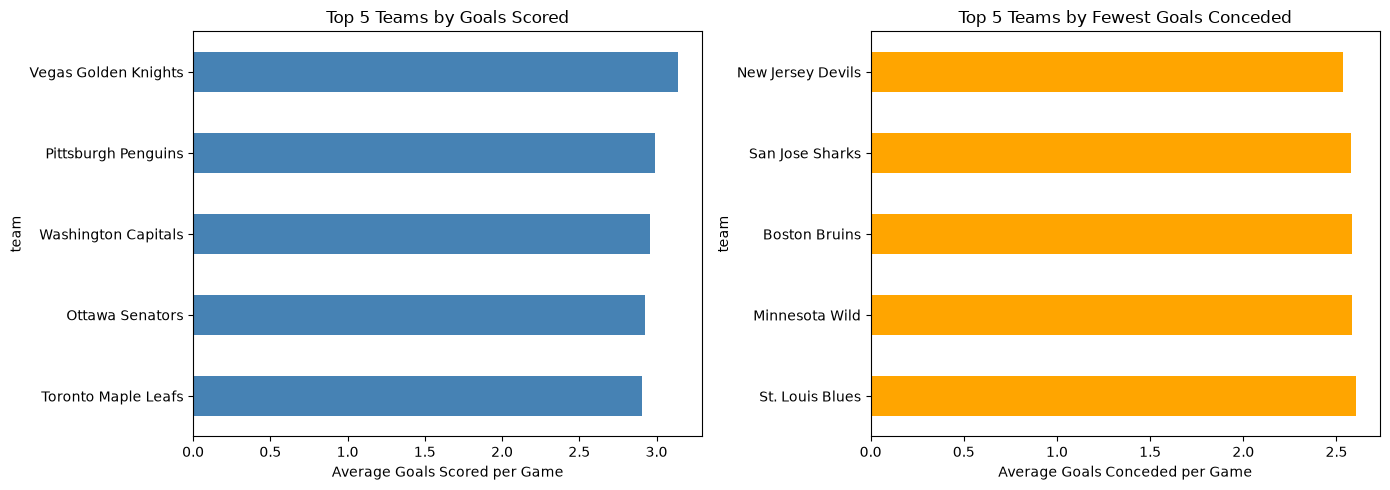

In [46]:
# Identify the top five high scoring teams and teams conceding the fewest goals
top_offense = team_summary["goals_scored"].nlargest(5)
top_defense = team_summary["goals_conceded"].nsmallest(5)

# Visualize team comparisons
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

top_offense.sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Top 5 Teams by Goals Scored")
ax[0].set_xlabel("Average Goals Scored per Game")

top_defense.sort_values(ascending=False).plot(kind="barh", ax=ax[1], color="orange")
ax[1].set_title("Top 5 Teams by Fewest Goals Conceded")
ax[1].set_xlabel("Average Goals Conceded per Game")

plt.tight_layout()
plt.show()

The Vegas Golden Knights have the highest offensive output (3.14 goals per game), although they have a smaller sample size (235 games), among the teams with at least 1500 games, the Pittsburgh Penguins were the highest scoring (2.99 goals per game). The New Jersey Devils conceded the fewest goals per game (2.54). Further analysis is needed to determine whether offensive or defensive performance is more strongly associated with winning games.

## 8. New Feature Engineering

**8.1 Differentials**

,goal_differential,shot_differential
count,23716.00,23716.00
mean,0.28,1.77
std,2.36,10.09
min,-9.00,-39.00
25%,-1.00,-5.00
50%,0.00,2.00
75%,2.00,9.00
max,10.00,45.00


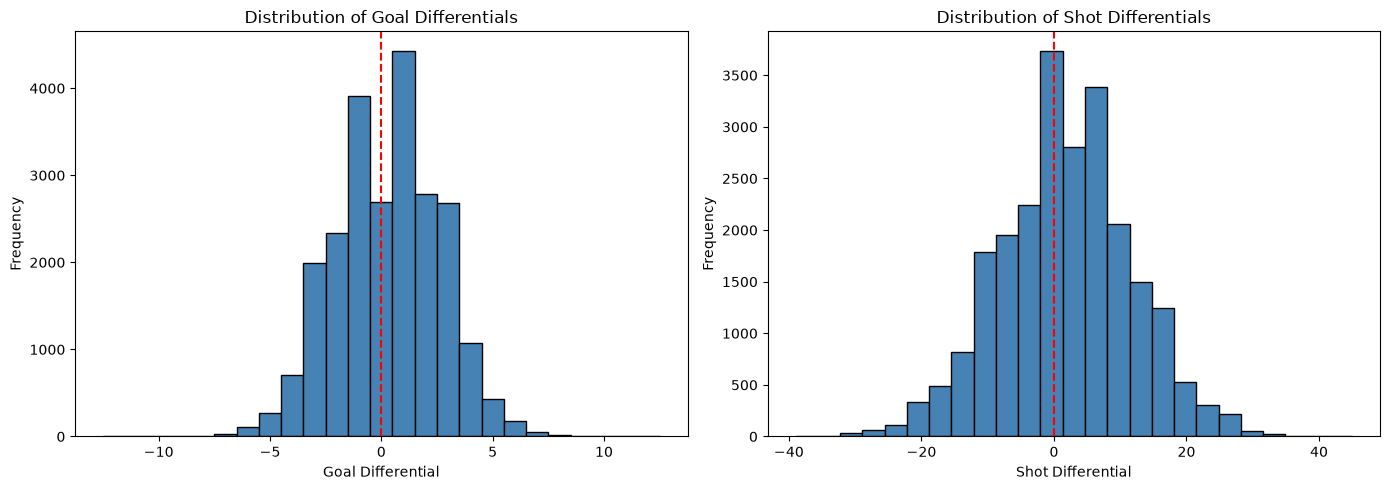

In [47]:
# New goal and shot differential columns
game_stats_clean["goal_differential"] = game_stats_clean["home_goals"] - game_stats_clean["away_goals"]
game_stats_clean["shot_differential"] = game_stats_clean["home_shots"] - game_stats_clean["away_shots"]

# Display descriptive statistics
display(game_stats_clean[["goal_differential", "shot_differential"]].describe().round(2))

# Visualize the distributions
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].hist(game_stats_clean["goal_differential"], bins=np.arange(-12.5, 13.5, 1), color="steelblue", edgecolor="black")
ax[0].set_title("Distribution of Goal Differentials")
ax[0].set_xlabel("Goal Differential")
ax[0].set_ylabel("Frequency")
ax[0].axvline(0, color="red", linestyle="--")

ax[1].hist(game_stats_clean["shot_differential"], bins=25, color="steelblue", edgecolor="black")
ax[1].set_title("Distribution of Shot Differentials")
ax[1].set_xlabel("Shot Differential")
ax[1].set_ylabel("Frequency")
ax[1].axvline(0, color="red", linestyle="--")

plt.tight_layout()
plt.show()

The goal and shot differentials are useful for measuring relative performance between opposing teams, rather than examining the stats independently. Both differentials have a positive mean (0.28 goals and 1.77 shots), providing further evidence of home advantage. The median goal differential is zero, while the median shot differential is two, which could indicate that home advantage may be more apparent in shot volume. However, when we refer back to the average number of home and away shots (30.67 and 28.90) versus goals (2.90 and 2.62) found in Section 4.1, I don't think we can read into this much, shots are over 10 times more frequent than goals. Furthermore, goal differentials are directly related to the game outcome, whereas a positive shot differential does not always translate into victory.

**8.2 Shooting Efficiency**

,home_shooting_percentage,away_shooting_percentage
count,23716.00,23716.00
mean,9.76,9.38
std,5.91,5.97
min,0.00,0.00
25%,5.41,5.00
50%,9.09,8.57
75%,13.33,13.04
max,45.45,43.75


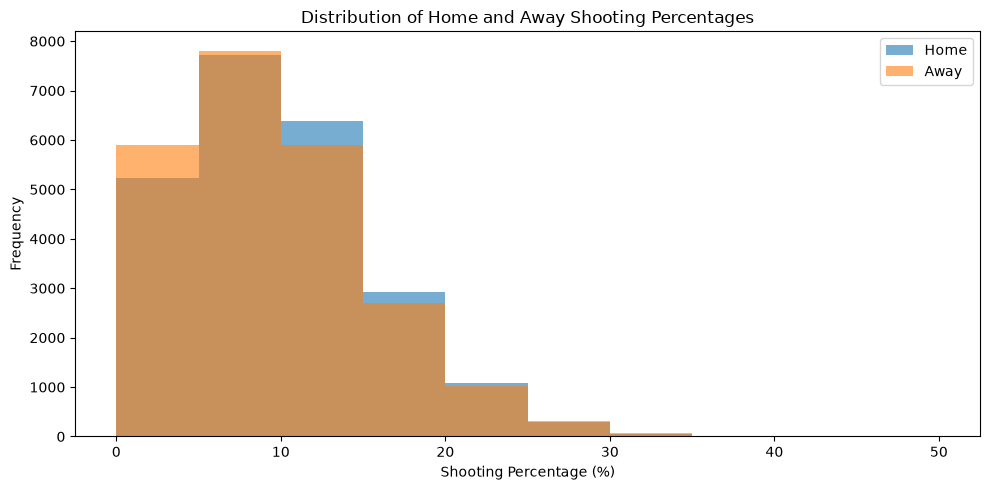

In [50]:
# Create shooting percentage columns
game_stats_clean["home_shooting_percentage"] = (
    game_stats_clean["home_goals"] / game_stats_clean["home_shots"] * 100
)

game_stats_clean["away_shooting_percentage"] = (
    game_stats_clean["away_goals"] / game_stats_clean["away_shots"] * 100
)

# Display descriptive statistics
display(game_stats_clean[[
    "home_shooting_percentage", "away_shooting_percentage"
]].describe().round(2))

# Visualize shooting percentage distributions
plt.figure(figsize=(10, 5))

bins = np.arange(0, 55, 5)

plt.hist(game_stats_clean["home_shooting_percentage"], bins=bins,
         alpha=0.6, label="Home")
plt.hist(game_stats_clean["away_shooting_percentage"], bins=bins,
         alpha=0.6, label="Away")

plt.title("Distribution of Home and Away Shooting Percentages")
plt.xlabel("Shooting Percentage (%)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

Shooting percentage measures offensive efficiency rather than offensive volume by calculating the proportion of shots converted into goals. Home teams have a slightly higher average (9.76% vs. 9.38%) and median (9.09% vs. 8.57%) shooting percentage. Both distributions have similar standard deviations (5.91 and 5.97 percentage points), this indicates similar variability. These results suggest that home teams not only take more shots but are also marginally better at converting them into goals.

The first time I ran this code I had a max value of 100% for both home and away shooting percentages. This came from the same game between the Colorado Avalanche and Phoenix Coyotes (April 12, 2006). This error was corrected in Section 3.4 using box score data from ESPN.

**8.3 Special Teams Efficiency**

In [49]:
# Calculate power-play percentages
game_stats_clean["home_power_play_percentage"] = (
    game_stats_clean["home_power_play_goals"] /
    game_stats_clean["home_power_play_opportunities"].replace(0, np.nan) * 100
)

game_stats_clean["away_power_play_percentage"] = (
    game_stats_clean["away_power_play_goals"] /
    game_stats_clean["away_power_play_opportunities"].replace(0, np.nan) * 100
)

# Calculate penalty-kill percentages
game_stats_clean["home_penalty_kill_percentage"] = 100 - game_stats_clean["away_power_play_percentage"]
game_stats_clean["away_penalty_kill_percentage"] = 100 - game_stats_clean["home_power_play_percentage"]

# Display descriptive statistics
display(game_stats_clean[[
    "home_power_play_percentage", "away_power_play_percentage",
    "home_penalty_kill_percentage", "away_penalty_kill_percentage"
]].describe().round(2))

,home_power_play_percentage,away_power_play_percentage,home_penalty_kill_percentage,away_penalty_kill_percentage
count,23479.00,23350.00,23350.00,23479.00
mean,18.57,17.43,82.57,81.43
std,22.47,23.09,23.09,22.47
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,66.67,66.67
50%,14.29,0.00,100.00,85.71
75%,33.33,33.33,100.00,100.00
max,100.00,100.00,100.00,100.00


Power-play and penalty-kill percentages measure how effectively teams capitalize on power-play opportunities and defend against opposing power plays. Home teams have higher average game-level power-play efficiency (18.57% vs. 17.43%) and penalty-kill efficiency (82.57% vs. 81.43%). Games without power-play opportunities were assigned missing efficiency values since their percentages cannot be calculated. Further analysis is needed to examine the relationship between special teams efficiency and winning games.

## 9. Trends Over Time

**9.1 Offensive Performance Over Time**

,home_goals,away_goals,home_shots,away_shots
season,,,,
2000,2.89,2.63,28.51,26.91
2001,2.76,2.48,28.43,26.73
2002,2.79,2.52,29.23,27.49
2003,2.69,2.45,29.16,26.95
2005,3.18,2.87,30.99,28.97
2006,3.03,2.73,30.60,28.57
2007,2.85,2.59,30.26,27.87
2008,3.02,2.68,31.26,29.15
2009,2.95,2.59,31.27,29.37


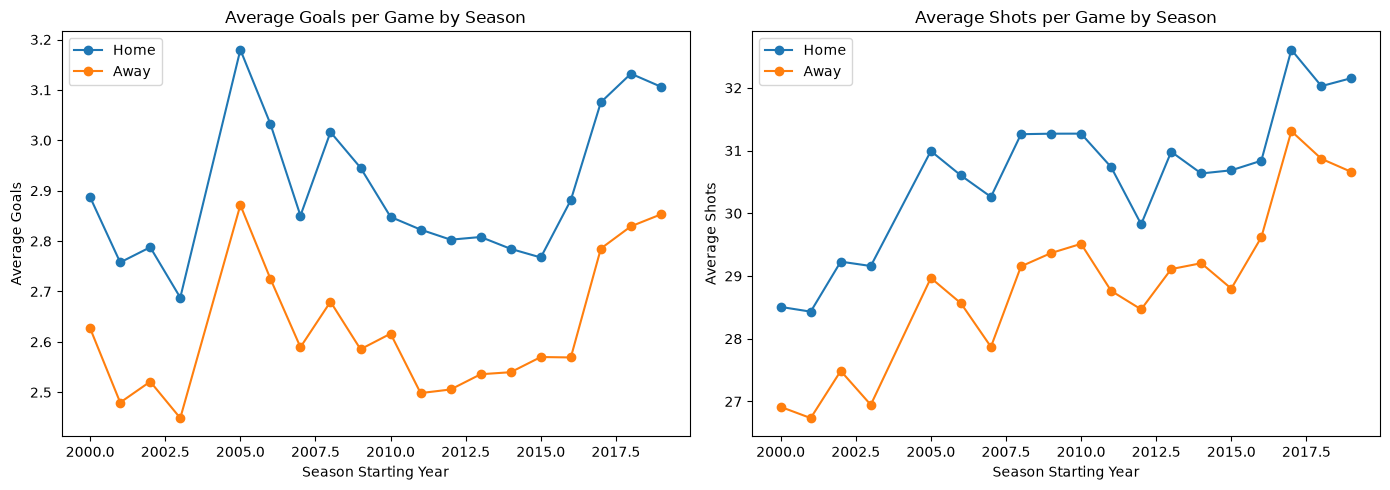

In [52]:
# Calculate average goals and shots for each season
season_stats = regular_season.groupby("season")[[
    "home_goals", "away_goals", "home_shots", "away_shots"
]].mean()

display(season_stats.round(2))

# Visualize offensive trends over time
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

season_stats[["home_goals", "away_goals"]].plot(ax=ax[0], marker="o")
ax[0].set_title("Average Goals per Game by Season")
ax[0].set_xlabel("Season Starting Year")
ax[0].set_ylabel("Average Goals")
ax[0].legend(["Home", "Away"])

season_stats[["home_shots", "away_shots"]].plot(ax=ax[1], marker="o")
ax[1].set_title("Average Shots per Game by Season")
ax[1].set_xlabel("Season Starting Year")
ax[1].set_ylabel("Average Shots")
ax[1].legend(["Home", "Away"])

plt.tight_layout()
plt.show()

These visualizations show that home teams consistently average more goals and shots than away teams. Scoring peaked in the 2005-06 season, when home and away teams averaged 3.18 and 2.87 goals, respectively. Shot volume increased over time, peaking during the 2017-18 season. Goals and shots do not always follow the same trends, suggesting that increased shot volume does not necessarily translate into increased scoring.

**9.2 Home Advantage Over Time**

,home_won,away_won,home_advantage
season,,,
2000,48.94,38.70,10.24
2001,49.27,38.62,10.65
2002,48.54,38.70,9.84
2003,47.97,38.21,9.76
2005,57.40,42.60,14.80
2006,55.04,44.96,10.08
2007,53.74,46.26,7.48
2008,55.85,44.15,11.71
2009,56.10,43.90,12.20


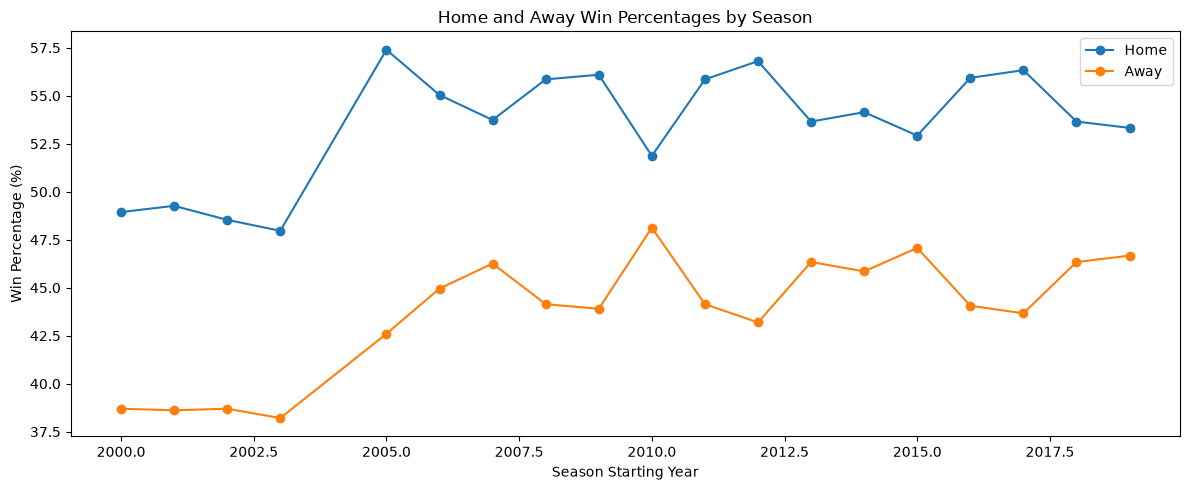

In [56]:
# Calculate home and away win percentages by season
season_wins = regular_season.groupby("season")[["home_won", "away_won"]].mean() * 100

# Calculate home advantage in percentage points by season
season_wins["home_advantage"] = season_wins["home_won"] - season_wins["away_won"]

display(season_wins.round(2))

# Graph win percentages over time
season_wins[["home_won", "away_won"]].plot(figsize=(12, 5), marker="o")

plt.title("Home and Away Win Percentages by Season")
plt.xlabel("Season Starting Year")
plt.ylabel("Win Percentage (%)")
plt.legend(["Home", "Away"])
plt.tight_layout()
plt.show()

Home teams have a higher win percentage across every season in the dataset. Home advantage was strongest in 2005-06 and weakest in 2010-11 (14.80 and 3.74 percentage points, respectively). Home advantage fluctuates consistently, there is no clear and consistent trend in either direction. Finally, the abolition of draws following the 2004-2005 lockout must be considered when comparing historical win percentages.

**9.3 Standardized Performance Trends**

,Goals,Shots,Penalty Minutes
season,,,
2000,1.00,1.00,1.00
2001,0.95,1.00,1.00
2002,0.96,1.02,0.96
2003,0.93,1.01,0.98
2005,1.10,1.08,1.06
2006,1.04,1.07,0.93
2007,0.99,1.05,0.92
2008,1.03,1.09,0.91
2009,1.00,1.09,0.84


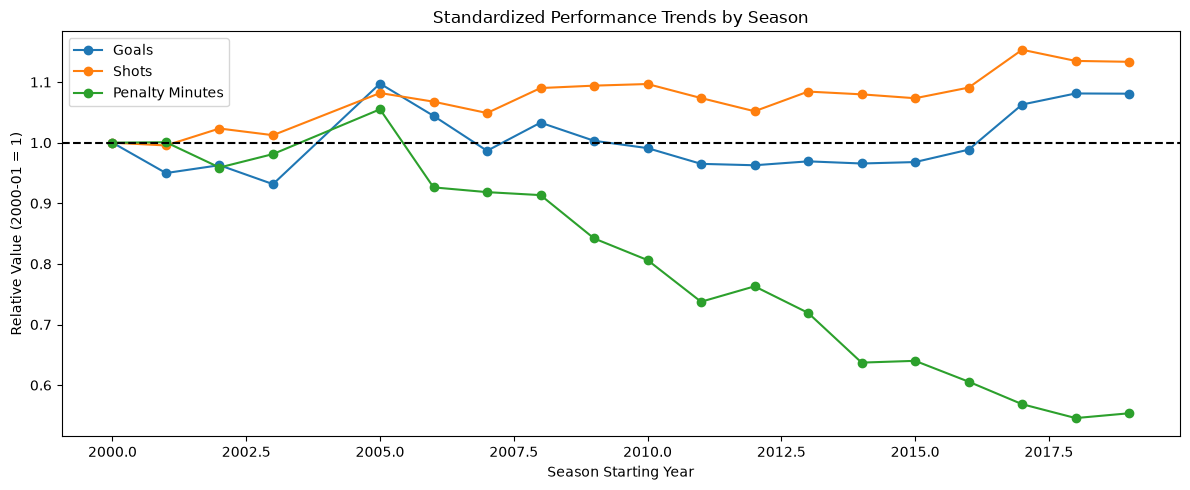

In [57]:
# Calculate the seasonal averages
season_trends = pd.DataFrame({
    "Goals": season_stats["home_goals"] + season_stats["away_goals"],
    "Shots": season_stats["home_shots"] + season_stats["away_shots"],
    "Penalty Minutes": regular_season.groupby("season")[
        ["home_penalty_minutes", "away_penalty_minutes"]
    ].mean().sum(axis=1)
})

# Standardize relative to the first season in the dataset (2000-01)
standardized_trends = season_trends / season_trends.loc[2000]

display(standardized_trends.round(2))

# Visualize standardized trends
standardized_trends.plot(figsize=(12, 5), marker="o")

plt.title("Standardized Performance Trends by Season")
plt.xlabel("Season Starting Year")
plt.ylabel("Relative Value (2000-01 = 1)")
plt.axhline(1, color="black", linestyle="--")
plt.tight_layout()
plt.show()

Standardizing the metrics relative to the 2000-01 season allows comparisons between variables with different numerical scales. By 2019-20, average goals and shots per game had increased by approximately 8% and 13%, respectively. Penalty minutes experienced the largest relative change, over 20 seasons it decreased by 45% compared to the base season. Goals and shots generally increased over the observed period, while penalty minutes followed a predominantly downward trend.

## 10. Variable Relationships

**10.1 Offensive vs. Defensive Performance**

In [58]:
# Copy home and away performance statistics
home_games = game_stats_clean[[
    "season", "game_type", "home_team", "home_goals",
    "away_goals", "home_shots", "away_shots", "home_won"
]].copy()

away_games = game_stats_clean[[
    "season", "game_type", "away_team", "away_goals",
    "home_goals", "away_shots", "home_shots", "away_won"
]].copy()

# Standardize column names for easy comparison and combine 
columns = ["season", "game_type", "team", "goals_scored",
           "goals_conceded", "shots_taken", "shots_conceded", "won"]

home_games.columns = columns
away_games.columns = columns

team_games = pd.concat([home_games, away_games], ignore_index=True)

# Isolate regular-season games
team_regular = team_games[team_games["game_type"] == "Regular Season"]

# Calculate average performance by team and season
metrics = ["goals_scored", "goals_conceded", "shots_taken", "shots_conceded"]

team_season_stats = team_regular.groupby(["season", "team"])[metrics + ["won"]].mean()

team_season_stats["won"] *= 100
team_season_stats = team_season_stats.rename(columns={"won": "win_percentage"})

display(team_season_stats.head().round(2))

goals_scored  goals_conceded  shots_taken  \
season team                                                           
2000   Anaheim Ducks              2.29            2.99        25.89   
       Atlanta Thrashers          2.57            3.52        27.94   
       Boston Bruins              2.77            3.04        28.77   
       Buffalo Sabres             2.66            2.24        26.88   
       Calgary Flames             2.40            2.88        27.20   

                          shots_conceded  win_percentage  
season team                                               
2000   Anaheim Ducks               29.48           30.49  
       Atlanta Thrashers           32.38           28.05  
       Boston Bruins               26.72           43.90  
       Buffalo Sabres              26.77           56.10  
       Calgary Flames              27.12           32.93

,Game Level,Season Level
goals_scored,0.594,0.695
goals_conceded,-0.577,-0.607
shots_taken,0.027,0.470
shots_conceded,-0.028,-0.311


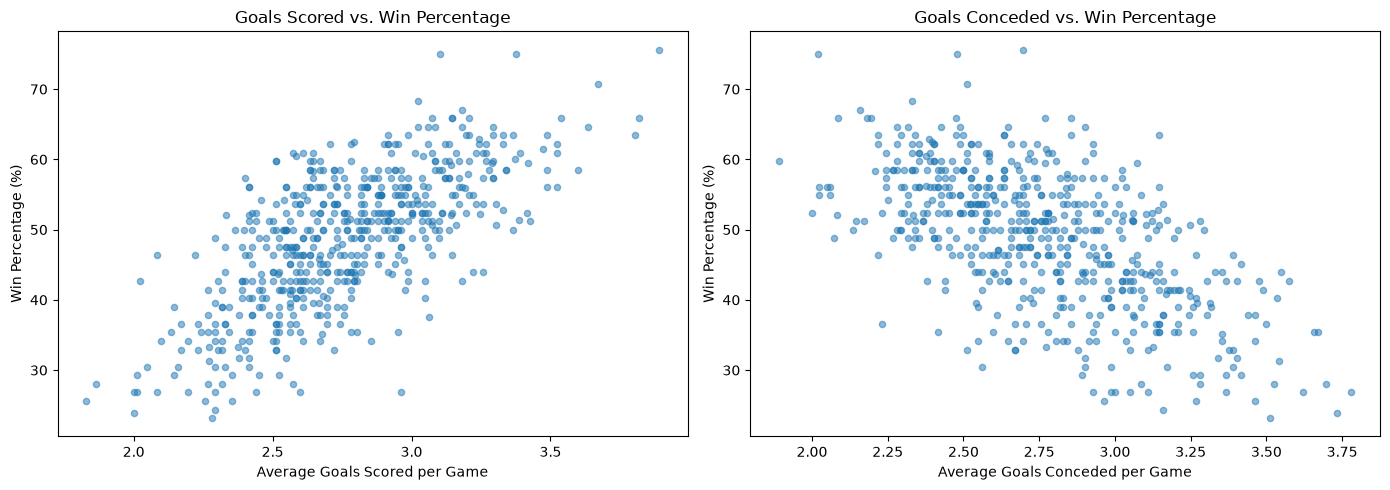

In [59]:
# Calculate correlations with winning
correlations = pd.DataFrame({
    "Game Level": team_regular[metrics + ["won"]].corr()["won"],
    "Season Level": team_season_stats[metrics + ["win_percentage"]].corr()["win_percentage"]
})

display(correlations.loc[metrics].round(3))

# Visualize offensive and defensive relationships
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

team_season_stats.plot(kind="scatter", x="goals_scored",
                       y="win_percentage", ax=ax[0], alpha=0.5)
ax[0].set_title("Goals Scored vs. Win Percentage")
ax[0].set_xlabel("Average Goals Scored per Game")
ax[0].set_ylabel("Win Percentage (%)")

team_season_stats.plot(kind="scatter", x="goals_conceded",
                       y="win_percentage", ax=ax[1], alpha=0.5)
ax[1].set_title("Goals Conceded vs. Win Percentage")
ax[1].set_xlabel("Average Goals Conceded per Game")
ax[1].set_ylabel("Win Percentage (%)")

plt.tight_layout()
plt.show()

Goals scored have a stronger correlation with winning than goals conceded at both the game level (0.594 vs. −0.577) and seasonal level (0.695 vs. −0.607), based on absolute correlation values. Shot volume has a negligible correlation with winning individual games but a stronger association with seasonal win percentages. All four relationships are stronger at the seasonal level than at the game level. These results suggest that offensive output is more strongly associated with regular-season success, although goals scored and conceded directly influence the outcome of games.

**10.2 Special Teams Efficiency vs. Winning**

In [66]:
# Select regular-season games with engineered features
special_regular = game_stats_clean[game_stats_clean["game_type"] == "Regular Season"]

# Select home and away special teams statistics
home_special = special_regular[[
    "season", "home_team", "home_won",
    "home_power_play_percentage", "home_penalty_kill_percentage",
    "home_power_play_goals", "home_power_play_opportunities",
    "away_power_play_goals", "away_power_play_opportunities"
]].copy()

away_special = special_regular[[
    "season", "away_team", "away_won",
    "away_power_play_percentage", "away_penalty_kill_percentage",
    "away_power_play_goals", "away_power_play_opportunities",
    "home_power_play_goals", "home_power_play_opportunities"
]].copy()

# Standardize column names and combine
columns = ["season", "team", "won", "power_play_percentage",
           "penalty_kill_percentage", "pp_goals", "pp_opportunities",
           "opp_pp_goals", "opp_pp_opportunities"]

home_special.columns = columns
away_special.columns = columns

team_special = pd.concat([home_special, away_special], ignore_index=True)

# Calculate seasonal totals
special_season_stats = team_special.groupby(["season", "team"])[[
    "pp_goals", "pp_opportunities", "opp_pp_goals", "opp_pp_opportunities"
]].sum()

# Calculate seasonal efficiency and win percentages
special_season_stats["power_play_percentage"] = (
    special_season_stats["pp_goals"] /
    special_season_stats["pp_opportunities"].replace(0, np.nan) * 100
)

special_season_stats["penalty_kill_percentage"] = 100 - (
    special_season_stats["opp_pp_goals"] /
    special_season_stats["opp_pp_opportunities"].replace(0, np.nan) * 100
)

special_season_stats["win_percentage"] = (
    team_special.groupby(["season", "team"])["won"].mean() * 100
)

display(special_season_stats.head().round(2))

pp_goals  pp_opportunities  opp_pp_goals  \
season team                                                          
2000   Anaheim Ducks          66.0             373.0          71.0   
       Atlanta Thrashers      54.0             395.0          90.0   
       Boston Bruins          64.0             390.0          65.0   
       Buffalo Sabres         60.0             373.0          40.0   
       Calgary Flames         65.0             435.0          76.0   

                          opp_pp_opportunities  power_play_percentage  \
season team                                                             
2000   Anaheim Ducks                     390.0                  17.69   
       Atlanta Thrashers                 408.0                  13.67   
       Boston Bruins                     377.0                  16.41   
       Buffalo Sabres                    334.0                  16.09   
       Calgary Flames                    378.0                  14.94   

                          penalty_kill_percentage  win_percentage  
season team                                                        
2000   Anaheim Ducks                        81.79           30.49  
       Atlanta Thrashers                    77.94           28.05  
       Boston Bruins                        82.76           43.90  
       Buffalo Sabres                       88.02           56.10  
       Calgary Flames                       79.89           32.93

,Game Level,Season Level
power_play_percentage,0.222,0.499
penalty_kill_percentage,0.216,0.300


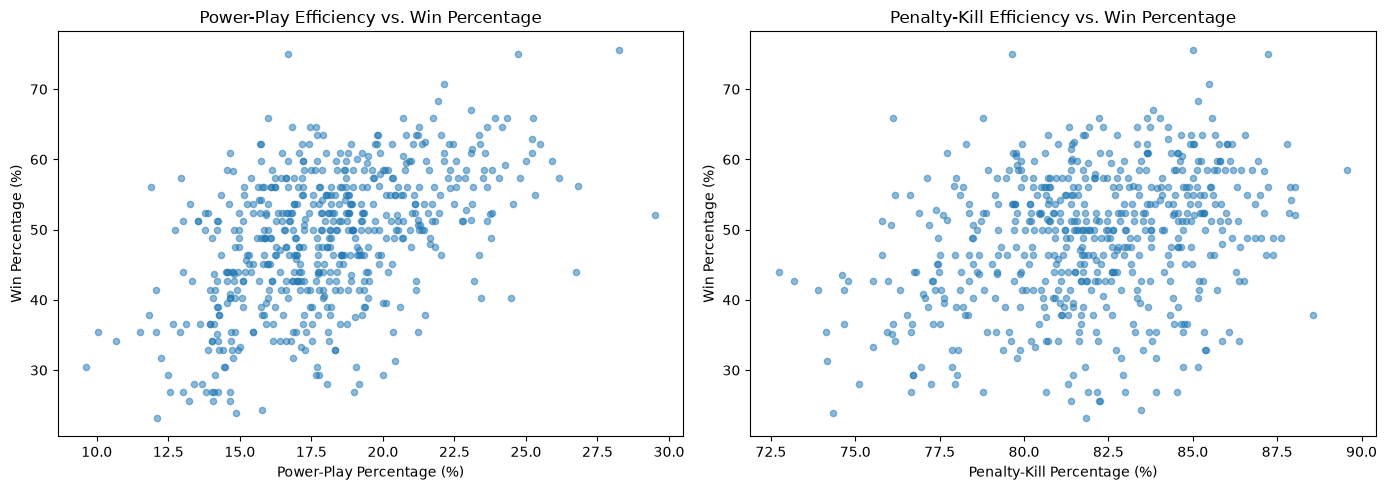

In [67]:
# Select variables and remove undefined percentages
special_metrics = ["power_play_percentage", "penalty_kill_percentage"]

special_game_valid = team_special[special_metrics + ["won"]].dropna()
special_season_valid = special_season_stats[
    special_metrics + ["win_percentage"]
].dropna()

# Calculate correlations with winning
special_correlations = pd.DataFrame({
    "Game Level": special_game_valid.corr()["won"],
    "Season Level": special_season_valid.corr()["win_percentage"]
})

display(special_correlations.loc[special_metrics].round(3))

# Visualize relationships
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

special_season_valid.plot(kind="scatter", x="power_play_percentage",
                         y="win_percentage", ax=ax[0], alpha=0.5)
ax[0].set_title("Power-Play Efficiency vs. Win Percentage")
ax[0].set_xlabel("Power-Play Percentage (%)")
ax[0].set_ylabel("Win Percentage (%)")

special_season_valid.plot(kind="scatter", x="penalty_kill_percentage",
                         y="win_percentage", ax=ax[1], alpha=0.5)
ax[1].set_title("Penalty-Kill Efficiency vs. Win Percentage")
ax[1].set_xlabel("Penalty-Kill Percentage (%)")
ax[1].set_ylabel("Win Percentage (%)")

plt.tight_layout()
plt.show()

Power-play and penalty-kill efficiencies are positively correlated with winning at the game and seasonal levels. Looking at the game level, the correlations are very close (0.222 for power-play efficiency and 0.216 for penalty-kill efficiency). The seasonal level, however, shows a much stronger correlation between win percentage and power-play efficiency (0.499) compared to win percentage and penalty-kill efficiency (0.300). Both special teams metrics have stronger associations with winning at the seasonal level.

**10.3 Regular-Season Performance vs. Playoff Success**

In [64]:
# Select playoff games from comparable seasons, Data earlier than 2010 is unavailable and 2019-20 had an unusual expanded format
team_playoffs = team_games[
    (team_games["game_type"] == "Playoffs") &
    (team_games["season"] >= 2010) &
    (team_games["season"] <= 2018)
]

# Calculate playoff games and victories by team for each season
playoff_stats = team_playoffs.groupby(["season", "team"])["won"].agg(["count", "sum"])
playoff_stats.columns = ["playoff_games", "playoff_wins"]

# Combine regular-season performance statistics
regular_stats = team_season_stats.join(
    special_season_stats[["power_play_percentage", "penalty_kill_percentage"]]
)

# Join regular-season statistics with playoff results
playoff_analysis = regular_stats.join(playoff_stats, how="inner")

display(playoff_analysis.round(2))

goals_scored  goals_conceded  shots_taken  \
season team                                                              
2010   Anaheim Ducks                 2.87            2.84        28.46   
       Boston Bruins                 2.98            2.30        32.88   
       Buffalo Sabres                2.93            2.78        32.80   
       Chicago Blackhawks            3.07            2.68        32.16   
       Detroit Red Wings             3.13            2.89        33.62   
...                                   ...             ...          ...   
2018   Tampa Bay Lightning           3.89            2.70        31.95   
       Toronto Maple Leafs           3.49            3.04        33.37   
       Vegas Golden Knights          3.00            2.78        34.32   
       Washington Capitals           3.34            3.02        30.39   
       Winnipeg Jets                 3.29            2.96        31.18   

                             shots_conceded  win_percentage  \
season team                                                   
2010   Anaheim Ducks                  32.30           57.32   
       Boston Bruins                  32.72           56.10   
       Buffalo Sabres                 30.66           52.44   
       Chicago Blackhawks             28.71           53.66   
       Detroit Red Wings              30.66           57.32   
...                                     ...             ...   
2018   Tampa Bay Lightning            32.11           75.61   
       Toronto Maple Leafs            33.13           56.10   
       Vegas Golden Knights           29.26           52.44   
       Washington Capitals            31.51           58.54   
       Winnipeg Jets                  33.43           57.32   

                             power_play_percentage  penalty_kill_percentage  \
season team                                                                   
2010   Anaheim Ducks                         23.51                    81.31   
       Boston Bruins                         16.23                    82.64   
       Buffalo Sabres                        19.35                    83.00   
       Chicago Blackhawks                    23.10                    79.22   
       Detroit Red Wings                     22.26                    82.33   
...                                            ...                      ...   
2018   Tampa Bay Lightning                   28.24                    85.02   
       Toronto Maple Leafs                   21.80                    79.90   
       Vegas Golden Knights                  16.81                    80.87   
       Washington Capitals                   20.76                    78.93   
       Winnipeg Jets                         24.80                    79.20   

                             playoff_games  playoff_wins  
season team                                               
2010   Anaheim Ducks                     6             2  
       Boston Bruins                    25            16  
       Buffalo Sabres                    7             3  
       Chicago Blackhawks                7             3  
       Detroit Red Wings                11             7  
...                                    ...           ...  
2018   Tampa Bay Lightning               4             0  
       Toronto Maple Leafs               7             3  
       Vegas Golden Knights              7             3  
       Washington Capitals               7             3  
       Winnipeg Jets                     6             2  

[144 rows x 9 columns]

goals_scored               0.032
goals_conceded            -0.217
shots_taken                0.138
shots_conceded            -0.121
power_play_percentage      0.005
penalty_kill_percentage    0.188
win_percentage             0.213
Name: playoff_wins, dtype: float64

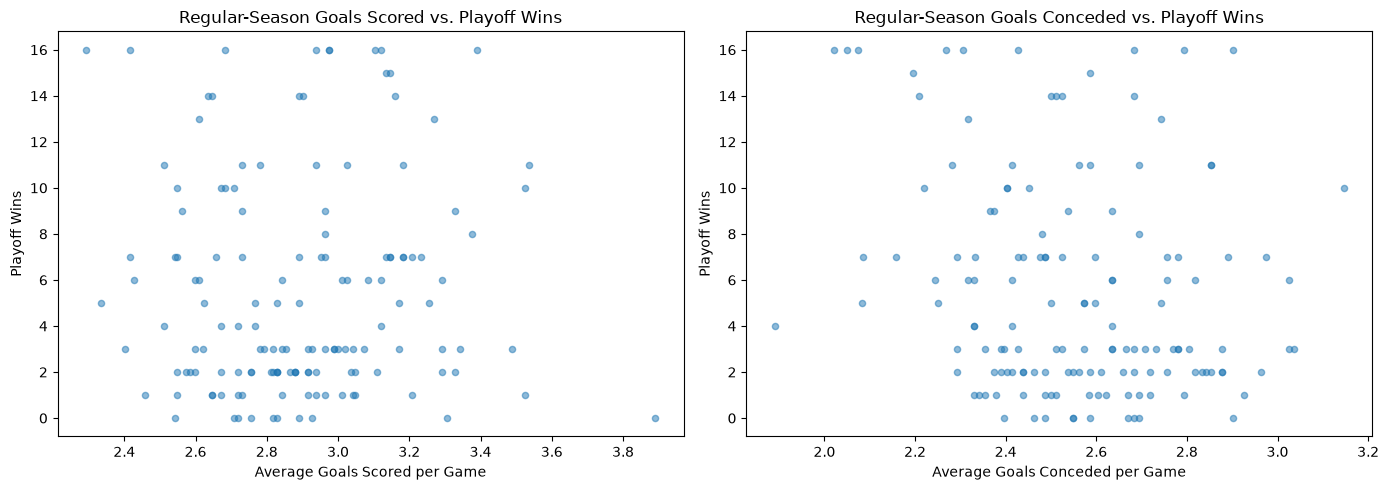

In [65]:
# Select regular-season performance metrics
playoff_metrics = [
    "goals_scored", "goals_conceded",
    "shots_taken", "shots_conceded",
    "power_play_percentage", "penalty_kill_percentage",
    "win_percentage"
]

# Calculate correlations using a common sample
playoff_valid = playoff_analysis[playoff_metrics + ["playoff_wins"]].dropna()

playoff_correlations = playoff_valid.corr()["playoff_wins"].drop("playoff_wins")

display(playoff_correlations.round(3))

# Visualize offensive and defensive relationships
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

playoff_valid.plot(kind="scatter", x="goals_scored",
                   y="playoff_wins", ax=ax[0], alpha=0.5)
ax[0].set_title("Regular-Season Goals Scored vs. Playoff Wins")
ax[0].set_xlabel("Average Goals Scored per Game")
ax[0].set_ylabel("Playoff Wins")

playoff_valid.plot(kind="scatter", x="goals_conceded",
                   y="playoff_wins", ax=ax[1], alpha=0.5)
ax[1].set_title("Regular-Season Goals Conceded vs. Playoff Wins")
ax[1].set_xlabel("Average Goals Conceded per Game")
ax[1].set_ylabel("Playoff Wins")

plt.tight_layout()
plt.show()

Goals conceded have the strongest absolute correlation with playoff victories (-0.217), followed closely by regular-season win percentage (0.213). Regular-season goals scored have a negligible correlation with playoff victories (0.032), suggesting that defensive performance may be more closely associated with postseason success. 

Compared to my findings in Section 10.2, penalty-kill efficiency has a stronger correlation with playoff success than power-play efficiency (0.188 vs. 0.005). All of the correlations are relatively weak, which suggests that strong regular-season performance does not necessarily translate into playoff success. This analysis covers 144 team-season observations from 2010-11 through 2018-19 and is limited to teams that qualified for the playoffs.

## 11. Hypothesis

**Hypothesis:** NHL teams that concede fewer goals per game during the regular season tend to achieve more playoff victories.

**Rationale:** My findings in Section 10.3 identified a stronger association between regular-season goals conceded and playoff victories (-0.217) than between goals scored and playoff victories. Furthermore, I wanted to test the common saying "Defense wins championships", or, in this case, playoff games.

**Independent variable (X):** Average regular-season goals conceded per game.

**Dependent variable (y):** Number of playoff victories in the corresponding season.

**Evaluation:** A simple linear regression will be used to determine how strongly regular-season goals conceded are associated with playoff victories and how much of the variation in playoff success can be explained by this metric.

**Limitations:** The sample size is smaller for playoff games, and this analysis only applies to teams that qualified for the playoffs.


## 12. Linear Regression

**12.1 Feature Selection and Model Training**

In [68]:
from sklearn.linear_model import LinearRegression

# Select feature and target
X = playoff_analysis[["goals_conceded"]]
y = playoff_analysis["playoff_wins"]

# Train the linear regression model
model = LinearRegression()
model.fit(X, y)

# Display model results
print("Coefficient:", round(model.coef_[0], 3))
print("Intercept:", round(model.intercept_, 3))
print("R-squared:", round(model.score(X, y), 4))

Coefficient: -4.428
Intercept: 16.801
R-squared: 0.0471


I trained my model using 144 team-season observations from 2010-11 through 2018-2019, the same sample that was selected in Section 10.3. The sample represents 16 playoff teams in each of those 9 seasons. The independent variable was average regular-season goals conceded per game. The dependent variable was playoff victories.

**12.2 Predicted vs. Actual Values**

Actual  Predicted
season team                                   
2010   Anaheim Ducks              2       4.22
       Boston Bruins             16       6.59
       Buffalo Sabres             3       4.49
       Chicago Blackhawks         3       4.92
       Detroit Red Wings          7       4.00
...                             ...        ...
2018   Tampa Bay Lightning        0       4.87
       Toronto Maple Leafs        3       3.35
       Vegas Golden Knights       3       4.49
       Washington Capitals        3       3.41
       Winnipeg Jets              2       3.68

[144 rows x 2 columns]

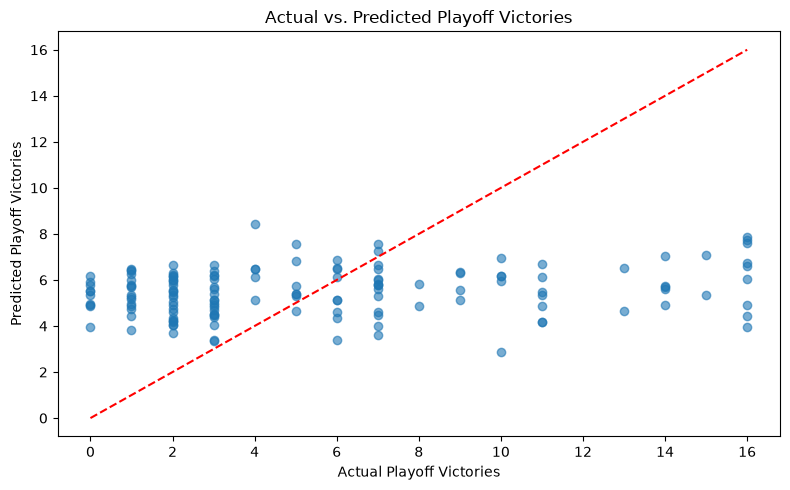

In [71]:
# Generate predictions
y_pred = model.predict(X)

# Compare actual and predicted playoff victories
predictions = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred
})

display(predictions.round(2))

# Visualize actual vs. predicted values
plt.figure(figsize=(8, 5))

plt.scatter(y, y_pred, alpha=0.6)
plt.plot([0, 16], [0, 16], color="red", linestyle="--")

plt.title("Actual vs. Predicted Playoff Victories")
plt.xlabel("Actual Playoff Victories")
plt.ylabel("Predicted Playoff Victories")
plt.tight_layout()
plt.show()

The model tends to overestimate playoff victories for less successful teams and underestimate them for more successful teams. For example, the model predicts 6.59 victories for the 2010-2011 Boston Bruins, who actually achieved 16. These predictions were generated using the same observations used to train the model.

**12.3 Regression Line**

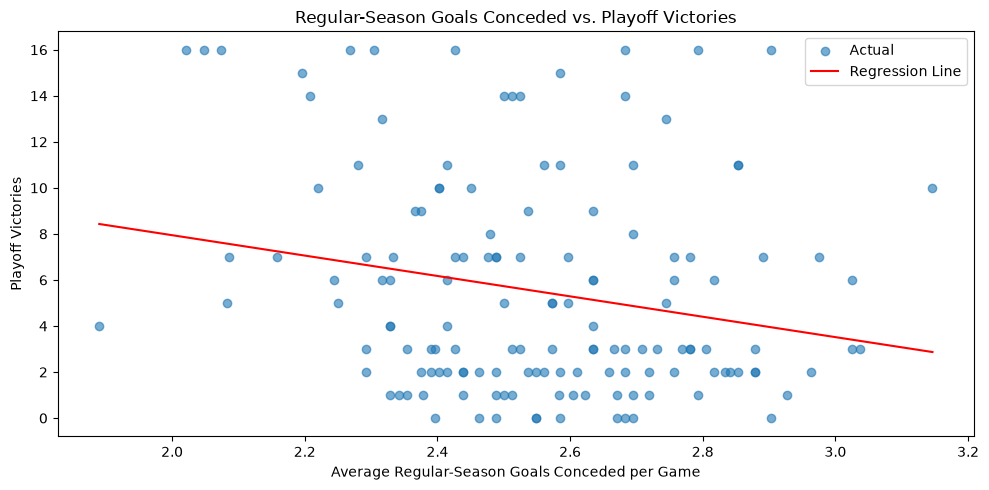

In [72]:
# Sort values to plot the regression line
X_sorted = X.sort_values("goals_conceded")

# Visualize actual observations and regression line
plt.figure(figsize=(10, 5))

plt.scatter(X["goals_conceded"], y, alpha=0.6, label="Actual")
plt.plot(X_sorted["goals_conceded"], model.predict(X_sorted),
         color="red", label="Regression Line")

plt.title("Regular-Season Goals Conceded vs. Playoff Victories")
plt.xlabel("Average Regular-Season Goals Conceded per Game")
plt.ylabel("Playoff Victories")
plt.legend()
plt.tight_layout()
plt.show()

The regression line has a negative slope, this is consistent with the expected relationship stated in Section 11. The observations are widely dispersed around the regression line, this indicates a weak linear relationship.

**12.4 Interpretation of Results**

The model's regression coefficient of -4.428 suggests that conceding one additional goal per game on average during the regular season is associated with approximately 4.43 fewer playoff victories. The 	$R^2$ of 0.0471 indicates that only 4.71% of the variation in playoff victories is explained by the model. Although the results are consistent with the direction of my hypothesis, regular-season goals conceded alone have limited explanatory power for playoff success. There are other factors that may influence postseason success, such as offesnive performance, injuries, goaltending, and the quality of playoff opponents. For example, if a team's strong regular-season defense relies on a player who gets injured before the playoffs, this could affect its postseason performance. My model does not take this into account. 

The analysis is also limited to teams that qualified for the playoffs, and the model has not been evaluated on unseen data. Given that the hypothesis was informed by the exploratory findings in Section 10.3, the regression provides further description of the relationship rather than independent confirmation.

## 13. Reflection / Conclusion